<a href="https://colab.research.google.com/github/RuthvikReddy4444/AIDL-PROJECT/blob/main/AIDL_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import shutil
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from collections import Counter

from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Google Drive dataset path
DRIVE_DATASET_PATH = "/content/drive/MyDrive/dataset/dataset"

# Local storage path
LOCAL_DATASET_PATH = "/content/dataset"

print("Google Drive Path:", DRIVE_DATASET_PATH)
print("Dataset Exists:", os.path.exists(DRIVE_DATASET_PATH))

if os.path.exists(DRIVE_DATASET_PATH):
    print("\nContents:")
    print(os.listdir(DRIVE_DATASET_PATH))
else:
    print("Dataset path not found. Check your Drive folder structure.")

Google Drive Path: /content/drive/MyDrive/dataset/dataset
Dataset Exists: True

Contents:
['train', 'test']


In [ ]:
if not os.path.exists(DRIVE_DATASET_PATH):
    raise FileNotFoundError("Google Drive dataset path not found!")

if os.path.exists(LOCAL_DATASET_PATH):
    shutil.rmtree(LOCAL_DATASET_PATH)

shutil.copytree(
    DRIVE_DATASET_PATH,
    LOCAL_DATASET_PATH
)

print("Dataset successfully copied!")
print("Local Dataset:", LOCAL_DATASET_PATH)

Dataset successfully copied!
Local Dataset: /content/dataset


In [ ]:
import os
import shutil
from tqdm import tqdm

SOURCE_PATH = "/content/dataset"

BINARY_PATH = "/content/binary_dataset"

# Mapping original categories to binary classes
CLASS_MAPPING = {
    "freshapples": "good",
    "freshbanana": "good",
    "freshoranges": "good",

    "unripe apple": "good",
    "unripe banana": "good",
    "unripe orange": "good",

    "rottenapples": "rotten",
    "rottenbanana": "rotten",
    "rottenoranges": "rotten"
}

IMAGE_EXTENSIONS = (
    ".jpg", ".jpeg", ".png",
    ".bmp", ".webp"
)

# Create destination directories
for split in ["train", "test"]:
    for class_name in ["good", "rotten"]:

        os.makedirs(
            os.path.join(BINARY_PATH, split, class_name),
            exist_ok=True
        )

# Copy images into their respective binary classes
for split in ["train", "test"]:

    source_split = os.path.join(SOURCE_PATH, split)

    for original_class in os.listdir(source_split):

        source_class_path = os.path.join(
            source_split, original_class
        )

        if not os.path.isdir(source_class_path):
            continue

        if original_class not in CLASS_MAPPING:
            print("Unknown category:", original_class)
            continue

        target_class = CLASS_MAPPING[original_class]

        destination_path = os.path.join(
            BINARY_PATH, split, target_class
        )

        for filename in tqdm(
            os.listdir(source_class_path),
            desc=f"{split}/{original_class}"
        ):

            if filename.lower().endswith(IMAGE_EXTENSIONS):

                source_file = os.path.join(
                    source_class_path, filename
                )

                destination_file = os.path.join(
                    destination_path,
                    f"{original_class}_{filename}"
                )

                shutil.copy2(
                    source_file,
                    destination_file
                )

print("\nBinary dataset created successfully!")

test/freshoranges: 100%|██████████| 388/388 [00:00<00:00, 3348.92it/s]


Binary dataset created successfully!


In [ ]:
import pandas as pd

dataset_summary = []

for split in ["train", "test"]:

    for class_name in ["good", "rotten"]:

        folder = os.path.join(
            BINARY_PATH, split, class_name
        )

        count = len([
            f for f in os.listdir(folder)
            if f.lower().endswith(IMAGE_EXTENSIONS)
        ])

        dataset_summary.append({
            "Dataset": split,
            "Class": class_name.upper(),
            "Image Count": count
        })

df = pd.DataFrame(dataset_summary)

display(df)

print("Total Images:", df["Image Count"].sum())

,Dataset,Class,Image Count
0,train,GOOD,10056
1,train,ROTTEN,6161
2,test,GOOD,2205
3,test,ROTTEN,1534


Total Images: 19956


In [ ]:
import os
from collections import defaultdict

DATASET_PATH = "/content/dataset"

CLASS_MAPPING = {
    "freshapples": "GOOD",
    "freshbanana": "GOOD",
    "freshoranges": "GOOD",
    "unripe apple": "GOOD",
    "unripe banana": "GOOD",
    "unripe orange": "GOOD",
    "rottenapples": "ROTTEN",
    "rottenbanana": "ROTTEN",
    "rottenoranges": "ROTTEN"
}

for split in ["train", "test"]:

    print(f"\n{'='*45}")
    print(f"{split.upper()} DATASET")
    print(f"{'='*45}")

    total = 0
    counts = defaultdict(int)

    for folder in sorted(os.listdir(
        os.path.join(DATASET_PATH, split)
    )):

        folder_path = os.path.join(
            DATASET_PATH, split, folder
        )

        if not os.path.isdir(folder_path):
            continue

        images = [
            f for f in os.listdir(folder_path)
            if f.lower().endswith(
                (".jpg", ".jpeg", ".png", ".webp", ".bmp")
            )
        ]

        label = CLASS_MAPPING.get(folder, "UNKNOWN")

        counts[label] += len(images)
        total += len(images)

        print(f"{folder:20} | {label:8} | {len(images)}")

    print("-"*45)
    print("GOOD TOTAL:", counts["GOOD"])
    print("ROTTEN TOTAL:", counts["ROTTEN"])
    print("TOTAL IMAGES:", total)


TRAIN DATASET
freshapples          | GOOD     | 1693
freshbanana          | GOOD     | 1581
freshoranges         | GOOD     | 1466
rottenapples         | ROTTEN   | 2342
rottenbanana         | ROTTEN   | 2224
rottenoranges        | ROTTEN   | 1595
unripe apple         | GOOD     | 1934
unripe banana        | GOOD     | 2097
unripe orange        | GOOD     | 1285
---------------------------------------------
GOOD TOTAL: 10056
ROTTEN TOTAL: 6161
TOTAL IMAGES: 16217

TEST DATASET
freshapples          | GOOD     | 395
freshbanana          | GOOD     | 381
freshoranges         | GOOD     | 388
rottenapples         | ROTTEN   | 601
rottenbanana         | ROTTEN   | 530
rottenoranges        | ROTTEN   | 403
unripe apple         | GOOD     | 371
unripe banana        | GOOD     | 400
unripe orange        | GOOD     | 270
---------------------------------------------
GOOD TOTAL: 2205
ROTTEN TOTAL: 1534
TOTAL IMAGES: 3739


In [ ]:
import os

# Main results directory in Google Drive
RESULTS_PATH = "/content/drive/MyDrive/dataset/results"

# Subdirectories for organizing experimental outputs
folders = [
    "saved_models",
    "model_weights",
    "training_history",
    "comparison_graphs",
    "confusion_matrices",
    "classification_reports",
    "predictions",
    "logs",
    "configurations",
    "checkpoints"
]

# Create directories
for folder in folders:
    os.makedirs(
        os.path.join(RESULTS_PATH, folder),
        exist_ok=True
    )

print("Results directory created successfully!")

print("\nMain Directory:", RESULTS_PATH)

print("\nCreated Folders:")
for folder in folders:
    print("  ✓", folder)

Results directory created successfully!

Main Directory: /content/drive/MyDrive/dataset/results

Created Folders:
  ✓ saved_models
  ✓ model_weights
  ✓ training_history
  ✓ comparison_graphs
  ✓ confusion_matrices
  ✓ classification_reports
  ✓ predictions
  ✓ logs
  ✓ configurations
  ✓ checkpoints


In [ ]:
def show_results_structure(path, indent=0):

    for item in sorted(os.listdir(path)):

        item_path = os.path.join(path, item)

        print("    " * indent + "|-- " + item)

        if os.path.isdir(item_path):
            show_results_structure(item_path, indent + 1)


show_results_structure(RESULTS_PATH)

|-- checkpoints
|-- classification_reports
|-- comparison_graphs
|-- configurations
|-- confusion_matrices
|-- logs
|-- model_weights
|-- predictions
|-- saved_models
|-- training_history


In [ ]:
import os
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from collections import Counter

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
DATASET_PATH = "/content/dataset"
RESULTS_PATH = "/content/drive/MyDrive/dataset/results"

TRAIN_PATH = os.path.join(DATASET_PATH, "train")
TEST_PATH = os.path.join(DATASET_PATH, "test")

CLASS_MAPPING = {
    "freshapples": 0,
    "freshbanana": 0,
    "freshoranges": 0,
    "unripe apple": 0,
    "unripe banana": 0,
    "unripe orange": 0,
    "rottenapples": 1,
    "rottenbanana": 1,
    "rottenoranges": 1
}

CLASS_NAMES = ["GOOD", "ROTTEN"]

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

print("Dataset Configuration Initialized!")
print("Image Size:", IMAGE_SIZE)
print("Batch Size:", BATCH_SIZE)
print("Classes:", CLASS_NAMES)

Dataset Configuration Initialized!
Image Size: (224, 224)
Batch Size: 32
Classes: ['GOOD', 'ROTTEN']


In [ ]:
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

def collect_image_paths(directory):

    image_paths = []
    labels = []

    for folder in sorted(os.listdir(directory)):

        folder_path = os.path.join(directory, folder)

        if not os.path.isdir(folder_path):
            continue

        if folder not in CLASS_MAPPING:
            print("Unknown folder:", folder)
            continue

        label = CLASS_MAPPING[folder]

        for filename in sorted(os.listdir(folder_path)):

            if filename.lower().endswith(IMAGE_EXTENSIONS):

                image_path = os.path.join(
                    folder_path, filename
                )

                image_paths.append(image_path)
                labels.append(label)

    return np.array(image_paths), np.array(labels, dtype=np.int32)


train_paths, train_labels = collect_image_paths(TRAIN_PATH)

test_paths, test_labels = collect_image_paths(TEST_PATH)

print("Training Images:", len(train_paths))
print("Testing Images:", len(test_paths))

print("\nTraining Class Distribution:")
print(Counter(train_labels))

print("\nTesting Class Distribution:")
print(Counter(test_labels))

Training Images: 16217
Testing Images: 3739

Training Class Distribution:
Counter({np.int32(0): 10056, np.int32(1): 6161})

Testing Class Distribution:
Counter({np.int32(0): 2205, np.int32(1): 1534})


In [ ]:
def load_and_resize_image(image_path, label):

    image = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        IMAGE_SIZE
    )

    image = tf.cast(image, tf.float32)

    return image, label

In [ ]:
def create_dataset(paths, labels, training=False):

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_and_resize_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset


train_dataset = create_dataset(
    train_paths,
    train_labels,
    training=True
)

test_dataset = create_dataset(
    test_paths,
    test_labels,
    training=False
)

print("Training Dataset Created!")
print("Testing Dataset Created!")

Training Dataset Created!
Testing Dataset Created!


In [ ]:
for images, labels in train_dataset.take(1):

    print("Image Batch Shape:", images.shape)
    print("Label Batch Shape:", labels.shape)

    print("Image Data Type:", images.dtype)
    print("Label Data Type:", labels.dtype)

    print("Minimum Pixel Value:", tf.reduce_min(images).numpy())
    print("Maximum Pixel Value:", tf.reduce_max(images).numpy())

Image Batch Shape: (32, 224, 224, 3)
Label Batch Shape: (32,)
Image Data Type: <dtype: 'float32'>
Label Data Type: <dtype: 'int32'>
Minimum Pixel Value: 0.0
Maximum Pixel Value: 255.0


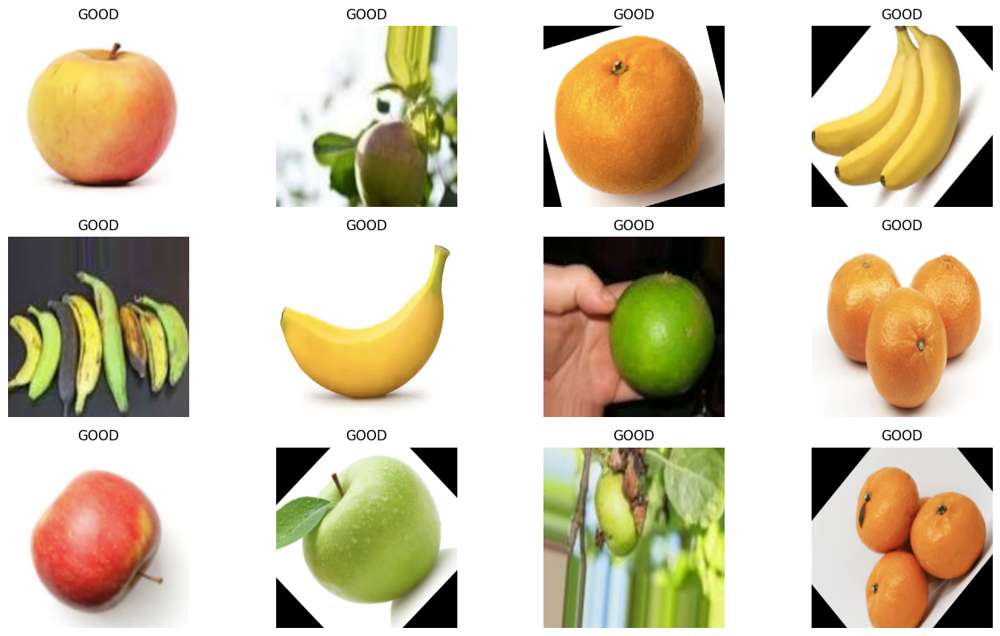

In [ ]:
plt.figure(figsize=(14, 8))

for images, labels in train_dataset.take(1):

    for i in range(12):

        plt.subplot(3, 4, i + 1)

        plt.imshow(
            images[i].numpy().astype("uint8")
        )

        label = CLASS_NAMES[int(labels[i].numpy())]

        plt.title(label)
        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import json

CONFIG = {
    "project": "Fruit Condition Classification",
    "framework": "TensorFlow",
    "classification_type": "Binary",
    "classes": CLASS_NAMES,
    "class_mapping": CLASS_MAPPING,
    "training_images": len(train_paths),
    "testing_images": len(test_paths),
    "image_size": list(IMAGE_SIZE),
    "batch_size": BATCH_SIZE,
    "random_seed": SEED,
    "additional_augmentation": False,
    "pretrained_backbone": "ImageNet",
    "backbone_trainable": False
}

config_path = os.path.join(
    RESULTS_PATH,
    "configurations",
    "dataset_config.json"
)

with open(config_path, "w") as file:
    json.dump(CONFIG, file, indent=4)

print("Configuration saved:", config_path)

Configuration saved: /content/drive/MyDrive/dataset/results/configurations/dataset_config.json


In [ ]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import json
import time

from tensorflow.keras import layers, models
from tensorflow.keras.applications import (
    ResNet50,
    ResNet101,
    DenseNet121,
    DenseNet169,
    EfficientNetB0,
    EfficientNetB1,
    MobileNetV2,
    MobileNetV3Large,
    InceptionV3,
    Xception
)

print("TensorFlow:", tf.__version__)
print("Available GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
Available GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
MODEL_CONFIGS = {
    "ResNet50": {
        "size": 224,
        "constructor": ResNet50,
        "preprocessing": "resnet"
    },

    "ResNet101": {
        "size": 224,
        "constructor": ResNet101,
        "preprocessing": "resnet"
    },

    "DenseNet121": {
        "size": 224,
        "constructor": DenseNet121,
        "preprocessing": "densenet"
    },

    "DenseNet169": {
        "size": 224,
        "constructor": DenseNet169,
        "preprocessing": "densenet"
    },

    "EfficientNetB0": {
        "size": 224,
        "constructor": EfficientNetB0,
        "preprocessing": "efficientnet"
    },

    "EfficientNetB1": {
        "size": 240,
        "constructor": EfficientNetB1,
        "preprocessing": "efficientnet"
    },

    "MobileNetV2": {
        "size": 224,
        "constructor": MobileNetV2,
        "preprocessing": "mobilenet"
    },

    "MobileNetV3Large": {
        "size": 224,
        "constructor": MobileNetV3Large,
        "preprocessing": "mobilenetv3"
    },

    "InceptionV3": {
        "size": 299,
        "constructor": InceptionV3,
        "preprocessing": "inception"
    },

    "Xception": {
        "size": 299,
        "constructor": Xception,
        "preprocessing": "xception"
    }
}

print("Total Models:", len(MODEL_CONFIGS))

for name, config in MODEL_CONFIGS.items():
    print(name, "->", config["size"])

Total Models: 10
ResNet50 -> 224
ResNet101 -> 224
DenseNet121 -> 224
DenseNet169 -> 224
EfficientNetB0 -> 224
EfficientNetB1 -> 240
MobileNetV2 -> 224
MobileNetV3Large -> 224
InceptionV3 -> 299
Xception -> 299


In [ ]:
from tensorflow.keras.applications.resnet import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.applications.inception_v3 import preprocess_input as inception_preprocess
from tensorflow.keras.applications.xception import preprocess_input as xception_preprocess

In [ ]:
def build_model(model_name):

    config = MODEL_CONFIGS[model_name]

    input_size = config["size"]

    inputs = layers.Input(
        shape=(input_size, input_size, 3),
        name="input_image"
    )

    constructor = config["constructor"]

    backbone = constructor(
        include_top=False,
        weights="imagenet",
        input_shape=(input_size, input_size, 3)
    )

    # Freeze pretrained backbone
    backbone.trainable = False

    if model_name == "MobileNetV3Large":
        backbone = constructor(
            include_top=False,
            weights="imagenet",
            input_shape=(input_size, input_size, 3),
            include_preprocessing=True
        )
        backbone.trainable = False

    if config["preprocessing"] in [
        "resnet", "densenet", "mobilenet",
        "inception", "xception"
    ]:

        preprocessing_functions = {
            "resnet": resnet_preprocess,
            "densenet": densenet_preprocess,
            "mobilenet": mobilenet_preprocess,
            "inception": inception_preprocess,
            "xception": xception_preprocess
        }

        x = layers.Lambda(
            preprocessing_functions[config["preprocessing"]]
        )(inputs)

    else:
        x = inputs

    x = backbone(x, training=False)

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(
        256,
        activation="relu"
    )(x)

    x = layers.Dropout(0.4)(x)

    outputs = layers.Dense(
        1,
        activation="sigmoid"
    )(x)

    model = models.Model(
        inputs=inputs,
        outputs=outputs,
        name=model_name
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.AUC(name="auc")
        ]
    )

    return model, backbone

In [ ]:
test_model, test_backbone = build_model("ResNet50")

test_model.summary()

print("\nBackbone Trainable:", test_backbone.trainable)

print(
    "Total Parameters:",
    test_model.count_params()
)

print(
    "Trainable Parameters:",
    sum(
        tf.keras.backend.count_params(w)
        for w in test_model.trainable_weights
    )
)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,112,513 (91.98 MB)

 Trainable params: 524,801 (2.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)


Backbone Trainable: False
Total Parameters: 24112513
Trainable Parameters: 524801


In [ ]:
import os
import gc
import json
import time
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications import (
    ResNet50,
    ResNet101,
    InceptionV3,
    Xception,
    DenseNet121,
    DenseNet169,
    EfficientNetB0,
    EfficientNetB1,
    MobileNetV2,
    MobileNetV3Large
)

from tensorflow.keras.applications.resnet import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.inception_v3 import preprocess_input as inception_preprocess
from tensorflow.keras.applications.xception import preprocess_input as xception_preprocess
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess

from tensorflow.keras.callbacks import ModelCheckpoint

from google.colab import drive

drive.mount('/content/drive')

SEED = 42

tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)

gpus = tf.config.list_physical_devices('GPU')

print("Available GPUs:", gpus)

for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
        print("Memory growth enabled:", gpu)

    except RuntimeError as e:
        print("GPU already initialized. Keeping existing configuration.")
        print(e)

print("GPU configuration checked!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU already initialized. Keeping existing configuration.
Physical devices cannot be modified after being initialized
GPU configuration checked!


In [ ]:
RESULTS_PATH = "/content/drive/MyDrive/dataset/results"

folders = [
    "saved_models",
    "model_weights",
    "training_history",
    "comparison_graphs",
    "confusion_matrices",
    "classification_reports",
    "predictions",
    "logs"
]

for folder in folders:
    os.makedirs(
        os.path.join(RESULTS_PATH, folder),
        exist_ok=True
    )

print("Experiment directories created successfully!")

for folder in folders:
    print("✓", folder)

Experiment directories created successfully!
✓ saved_models
✓ model_weights
✓ training_history
✓ comparison_graphs
✓ confusion_matrices
✓ classification_reports
✓ predictions
✓ logs



STARTING MODEL: ResNet50
Image Size: 224
Epochs: 20
Batch Size: 32

Model created successfully!

Training started: ResNet50
Epoch 1/20
507/507 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.9559 - auc: 0.9897 - loss: 0.1012 - precision: 0.9413 - recall: 0.9440
Epoch 1: saving model to /content/drive/MyDrive/dataset/results/model_weights/ResNet50_epoch01.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/dataset/results/model_weights/ResNet50_epoch01.weights.h5
507/507 ━━━━━━━━━━━━━━━━━━━━ 94s 160ms/step - accuracy: 0.9780 - auc: 0.9977 - loss: 0.0536 - precision: 0.9723 - recall: 0.9696 - val_accuracy: 0.9848 - val_auc: 0.9966 - val_loss: 0.0487 - val_precision: 0.9920 - val_recall: 0.9707
Epoch 2/20
507/507 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - accuracy: 0.9908 - auc: 0.9987 - loss: 0.0267 - precision: 0.9872 - recall: 0.9887
Epoch 2: saving model to /content/drive/MyDrive/dataset/results/model_weights/ResNet50_epoch02.weights.h5

Epoch 2: finished saving model to 

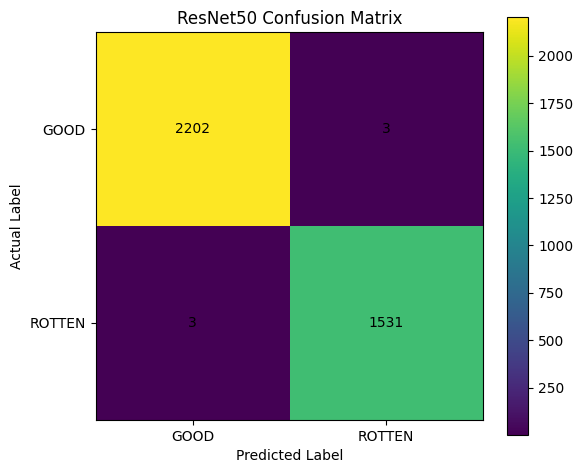


--------------------------------------------------
MODEL COMPLETED: ResNet50
--------------------------------------------------
Accuracy  : 0.9984
Precision : 0.9980
Recall    : 0.9980
F1 Score  : 0.9980
AUC       : 0.9997
Time      : 13.69 minutes

Comparison results updated!

STARTING MODEL: ResNet101
Image Size: 224
Epochs: 20
Batch Size: 32
171446536/171446536 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

Model created successfully!

Training started: ResNet101
Epoch 1/20
507/507 ━━━━━━━━━━━━━━━━━━━━ 0s 186ms/step - accuracy: 0.9620 - auc: 0.9910 - loss: 0.0922 - precision: 0.9499 - recall: 0.9504
Epoch 1: saving model to /content/drive/MyDrive/dataset/results/model_weights/ResNet101_epoch01.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/dataset/results/model_weights/ResNet101_epoch01.weights.h5
507/507 ━━━━━━━━━━━━━━━━━━━━ 153s 259ms/step - accuracy: 0.9823 - auc: 0.9983 - loss: 0.0467 - precision: 0.9771 - recall: 0.9763 - val_accuracy: 0.9917 - val_auc: 0.9981 - val_l

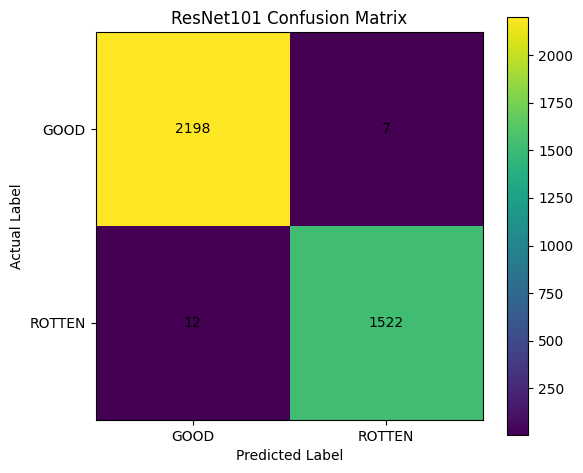


--------------------------------------------------
MODEL COMPLETED: ResNet101
--------------------------------------------------
Accuracy  : 0.9949
Precision : 0.9954
Recall    : 0.9922
F1 Score  : 0.9938
AUC       : 0.9995
Time      : 11.40 minutes

Comparison results updated!

STARTING MODEL: DenseNet121
Image Size: 224
Epochs: 20
Batch Size: 32
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Model created successfully!

Training started: DenseNet121
Epoch 1/20
507/507 ━━━━━━━━━━━━━━━━━━━━ 0s 208ms/step - accuracy: 0.9496 - auc: 0.9851 - loss: 0.1219 - precision: 0.9341 - recall: 0.9331
Epoch 1: saving model to /content/drive/MyDrive/dataset/results/model_weights/DenseNet121_epoch01.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/dataset/results/model_weights/DenseNet121_epoch01.weights.h5
507/507 ━━━━━━━━━━━━━━━━━━━━ 257s 365ms/step - accuracy: 0.9746 - auc: 0.9968 - loss: 0.0675 - precision: 0.9675 - recall: 0.9656 - val_accuracy: 0.9864 - val_auc: 0.9990 

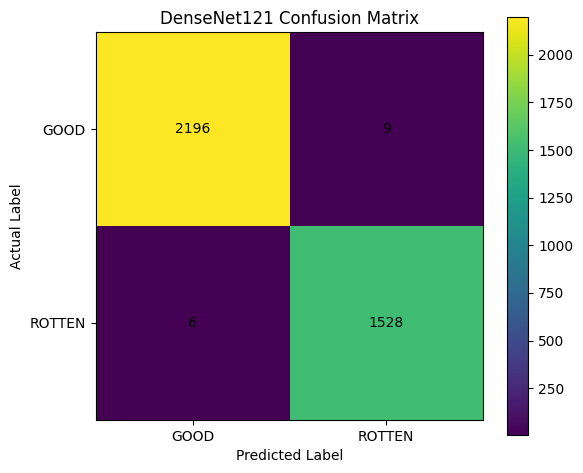


--------------------------------------------------
MODEL COMPLETED: DenseNet121
--------------------------------------------------
Accuracy  : 0.9960
Precision : 0.9941
Recall    : 0.9961
F1 Score  : 0.9951
AUC       : 0.9997
Time      : 16.08 minutes

Comparison results updated!

STARTING MODEL: DenseNet169
Image Size: 224
Epochs: 20
Batch Size: 32
51877672/51877672 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

Model created successfully!

Training started: DenseNet169
Epoch 1/20
507/507 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step - accuracy: 0.9456 - auc: 0.9810 - loss: 0.1259 - precision: 0.9295 - recall: 0.9275
Epoch 1: saving model to /content/drive/MyDrive/dataset/results/model_weights/DenseNet169_epoch01.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/dataset/results/model_weights/DenseNet169_epoch01.weights.h5
507/507 ━━━━━━━━━━━━━━━━━━━━ 230s 339ms/step - accuracy: 0.9761 - auc: 0.9974 - loss: 0.0612 - precision: 0.9700 - recall: 0.9671 - val_accuracy: 0.9832 - val_auc: 0.998

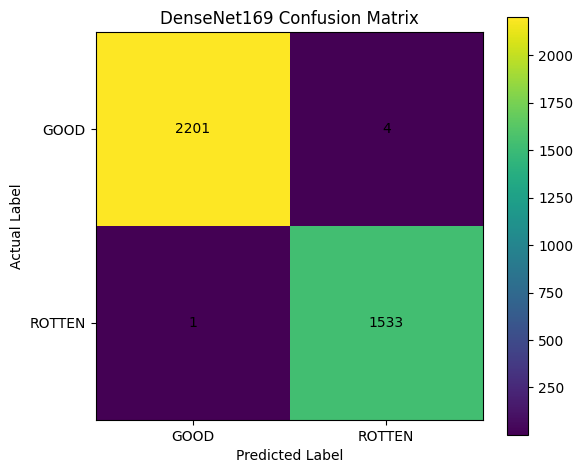


--------------------------------------------------
MODEL COMPLETED: DenseNet169
--------------------------------------------------
Accuracy  : 0.9987
Precision : 0.9974
Recall    : 0.9993
F1 Score  : 0.9984
AUC       : 1.0000
Time      : 16.82 minutes

Comparison results updated!

STARTING MODEL: EfficientNetB0
Image Size: 224
Epochs: 20
Batch Size: 32
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Model created successfully!

Training started: EfficientNetB0
Epoch 1/20
507/507 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step - accuracy: 0.9660 - auc: 0.9923 - loss: 0.0871 - precision: 0.9558 - recall: 0.9545
Epoch 1: saving model to /content/drive/MyDrive/dataset/results/model_weights/EfficientNetB0_epoch01.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/dataset/results/model_weights/EfficientNetB0_epoch01.weights.h5
507/507 ━━━━━━━━━━━━━━━━━━━━ 178s 249ms/step - accuracy: 0.9834 - auc: 0.9985 - loss: 0.0469 - precision: 0.9795 - recall: 0.9766 - val_accuracy: 0.9888 - va

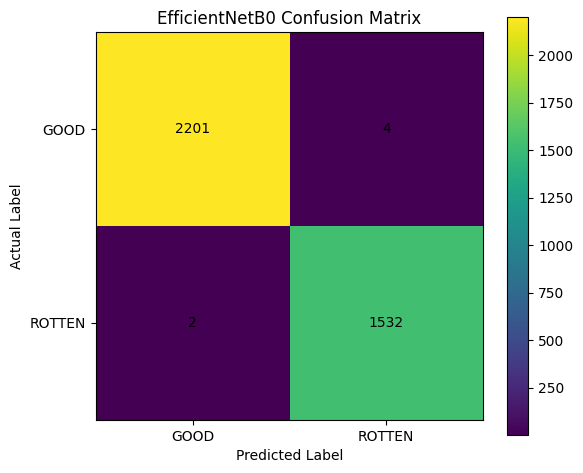


--------------------------------------------------
MODEL COMPLETED: EfficientNetB0
--------------------------------------------------
Accuracy  : 0.9984
Precision : 0.9974
Recall    : 0.9987
F1 Score  : 0.9980
AUC       : 0.9998
Time      : 16.18 minutes

Comparison results updated!

STARTING MODEL: EfficientNetB1
Image Size: 240
Epochs: 20
Batch Size: 32
27018416/27018416 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Model created successfully!

Training started: EfficientNetB1
Epoch 1/20
507/507 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step - accuracy: 0.9612 - auc: 0.9897 - loss: 0.0964 - precision: 0.9499 - recall: 0.9473
Epoch 1: saving model to /content/drive/MyDrive/dataset/results/model_weights/EfficientNetB1_epoch01.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/dataset/results/model_weights/EfficientNetB1_epoch01.weights.h5
507/507 ━━━━━━━━━━━━━━━━━━━━ 229s 338ms/step - accuracy: 0.9809 - auc: 0.9984 - loss: 0.0506 - precision: 0.9764 - recall: 0.9734 - val_accuracy: 0.9882 -

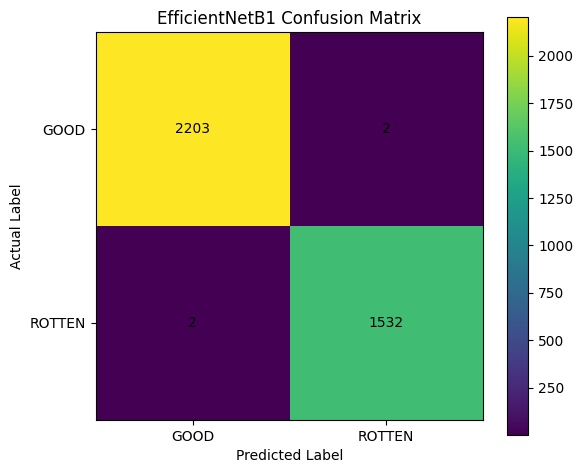


--------------------------------------------------
MODEL COMPLETED: EfficientNetB1
--------------------------------------------------
Accuracy  : 0.9989
Precision : 0.9987
Recall    : 0.9987
F1 Score  : 0.9987
AUC       : 1.0000
Time      : 17.21 minutes

Comparison results updated!

STARTING MODEL: MobileNetV2
Image Size: 224
Epochs: 20
Batch Size: 32
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Model created successfully!

Training started: MobileNetV2
Epoch 1/20
507/507 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.9477 - auc: 0.9853 - loss: 0.1156 - precision: 0.9329 - recall: 0.9282
Epoch 1: saving model to /content/drive/MyDrive/dataset/results/model_weights/MobileNetV2_epoch01.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/dataset/results/model_weights/MobileNetV2_epoch01.weights.h5
507/507 ━━━━━━━━━━━━━━━━━━━━ 100s 157ms/step - accuracy: 0.9747 - auc: 0.9971 - loss: 0.0632 - precision: 0.9679 - recall: 0.9653 - val_accuracy: 0.9880 - val_auc: 0.99

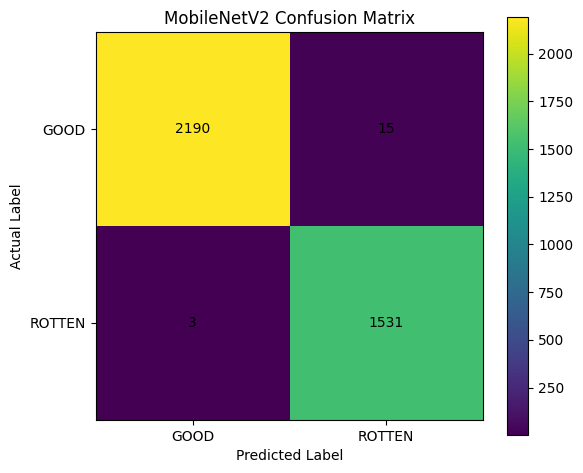


--------------------------------------------------
MODEL COMPLETED: MobileNetV2
--------------------------------------------------
Accuracy  : 0.9952
Precision : 0.9903
Recall    : 0.9980
F1 Score  : 0.9942
AUC       : 0.9999
Time      : 8.07 minutes

Comparison results updated!

STARTING MODEL: MobileNetV3Large
Image Size: 224
Epochs: 20
Batch Size: 32
12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Model created successfully!

Training started: MobileNetV3Large
Epoch 1/20
507/507 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.9613 - auc: 0.9890 - loss: 0.0957 - precision: 0.9517 - recall: 0.9472
Epoch 1: saving model to /content/drive/MyDrive/dataset/results/model_weights/MobileNetV3Large_epoch01.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/dataset/results/model_weights/MobileNetV3Large_epoch01.weights.h5
507/507 ━━━━━━━━━━━━━━━━━━━━ 134s 201ms/step - accuracy: 0.9817 - auc: 0.9983 - loss: 0.0476 - precision: 0.9778 - recall: 0.9740 - val_accuracy: 0.99

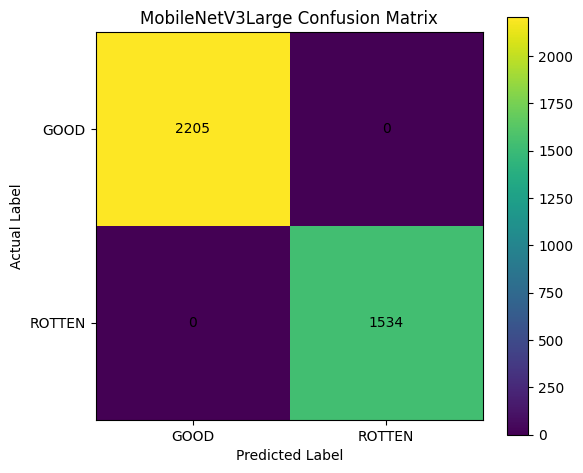


--------------------------------------------------
MODEL COMPLETED: MobileNetV3Large
--------------------------------------------------
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1 Score  : 1.0000
AUC       : 1.0000
Time      : 17.08 minutes

Comparison results updated!

STARTING MODEL: InceptionV3
Image Size: 299
Epochs: 20
Batch Size: 32
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

Model created successfully!

Training started: InceptionV3
Epoch 1/20
507/507 ━━━━━━━━━━━━━━━━━━━━ 0s 208ms/step - accuracy: 0.9206 - auc: 0.9663 - loss: 0.1896 - precision: 0.9042 - recall: 0.8810
Epoch 1: saving model to /content/drive/MyDrive/dataset/results/model_weights/InceptionV3_epoch01.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/dataset/results/model_weights/InceptionV3_epoch01.weights.h5
507/507 ━━━━━━━━━━━━━━━━━━━━ 214s 329ms/step - accuracy: 0.9600 - auc: 0.9933 - loss: 0.1021 - precision: 0.9520 - recall: 0.9422 - val_accuracy: 0.9821 - val_auc: 

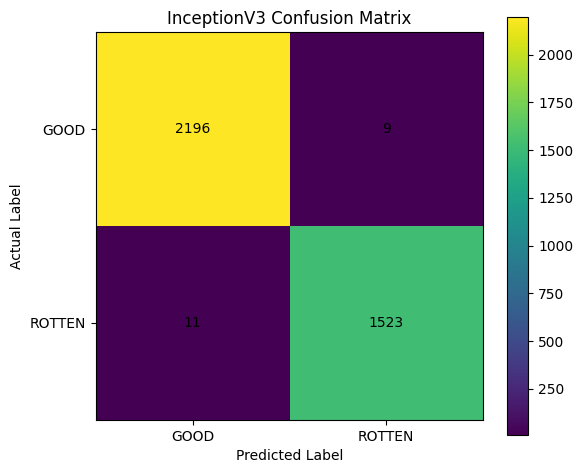


--------------------------------------------------
MODEL COMPLETED: InceptionV3
--------------------------------------------------
Accuracy  : 0.9947
Precision : 0.9941
Recall    : 0.9928
F1 Score  : 0.9935
AUC       : 0.9999
Time      : 21.24 minutes

Comparison results updated!

STARTING MODEL: Xception
Image Size: 299
Epochs: 20
Batch Size: 32
83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Model created successfully!

Training started: Xception
Epoch 1/20
507/507 ━━━━━━━━━━━━━━━━━━━━ 0s 347ms/step - accuracy: 0.9443 - auc: 0.9838 - loss: 0.1340 - precision: 0.9365 - recall: 0.9137
Epoch 1: saving model to /content/drive/MyDrive/dataset/results/model_weights/Xception_epoch01.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/dataset/results/model_weights/Xception_epoch01.weights.h5
507/507 ━━━━━━━━━━━━━━━━━━━━ 290s 487ms/step - accuracy: 0.9716 - auc: 0.9962 - loss: 0.0751 - precision: 0.9671 - recall: 0.9578 - val_accuracy: 0.9850 - val_auc: 0.9992 - val_loss

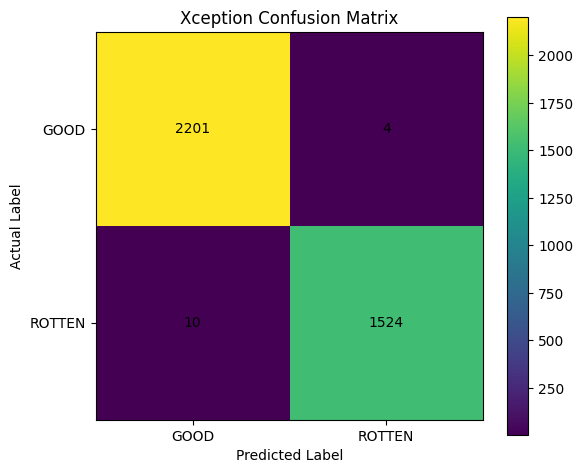


--------------------------------------------------
MODEL COMPLETED: Xception
--------------------------------------------------
Accuracy  : 0.9963
Precision : 0.9974
Recall    : 0.9935
F1 Score  : 0.9954
AUC       : 0.9997
Time      : 39.41 minutes

Comparison results updated!

ALL MODEL TRAINING COMPLETED
           Model  Image Size  Accuracy  Precision   Recall  F1 Score      AUC  Training Time (Minutes)
MobileNetV3Large         224  1.000000   1.000000 1.000000  1.000000 1.000000                17.079274
  EfficientNetB1         240  0.998930   0.998696 0.998696  0.998696 0.999996                17.207221
     DenseNet169         224  0.998663   0.997398 0.999348  0.998372 0.999982                16.818112
        ResNet50         224  0.998395   0.998044 0.998044  0.998044 0.999664                13.686970
  EfficientNetB0         224  0.998395   0.997396 0.998696  0.998046 0.999767                16.183753
        Xception         299  0.996256   0.997382 0.993481  0.995428 0.99

In [ ]:
# ============================================
# FRUIT CONDITION CLASSIFICATION
# AUTOMATED TRAINING OF 10 CNN MODELS
# ============================================

import os
import gc
import json
import time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# --------------------------------------------
# 1. TRAINING CONFIGURATION
# --------------------------------------------

EPOCHS = 20

MODEL_NAMES = [
    "ResNet50",
    "ResNet101",
    "DenseNet121",
    "DenseNet169",
    "EfficientNetB0",
    "EfficientNetB1",
    "MobileNetV2",
    "MobileNetV3Large",
    "InceptionV3",
    "Xception"
]

# Use existing results directory
for folder in [
    "saved_models",
    "model_weights",
    "training_history",
    "comparison_graphs",
    "confusion_matrices",
    "classification_reports",
    "predictions",
    "logs"
]:
    os.makedirs(os.path.join(RESULTS_PATH, folder), exist_ok=True)

# --------------------------------------------
# 2. MODEL-SPECIFIC DATASET
# --------------------------------------------

def create_model_dataset(paths, labels, image_size, training=False):

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    def load_image(path, label):

        image = tf.io.read_file(path)

        image = tf.io.decode_image(
            image,
            channels=3,
            expand_animations=False
        )

        image.set_shape([None, None, 3])

        image = tf.image.resize(
            image,
            (image_size, image_size)
        )

        image = tf.cast(image, tf.float32)

        return image, label

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


# --------------------------------------------
# 3. STORAGE FOR COMPARISON RESULTS
# --------------------------------------------

comparison_path = os.path.join(
    RESULTS_PATH,
    "model_comparison.csv"
)

if os.path.exists(comparison_path):
    comparison_df = pd.read_csv(comparison_path)
else:
    comparison_df = pd.DataFrame()


# --------------------------------------------
# 4. TRAIN EACH MODEL
# --------------------------------------------

for model_name in MODEL_NAMES:

    print("\n" + "=" * 65)
    print("STARTING MODEL:", model_name)
    print("=" * 65)

    # Skip models already completed
    if (
        not comparison_df.empty
        and "Model" in comparison_df.columns
        and model_name in comparison_df["Model"].values
    ):
        print("Already completed. Skipping:", model_name)
        continue

    tf.keras.backend.clear_session()
    gc.collect()

    start_time = time.time()

    # Get architecture-specific image size
    image_size = MODEL_CONFIGS[model_name]["size"]

    print("Image Size:", image_size)
    print("Epochs:", EPOCHS)
    print("Batch Size:", BATCH_SIZE)

    # Create datasets for this model
    train_ds = create_model_dataset(
        train_paths,
        train_labels,
        image_size,
        training=True
    )

    test_ds = create_model_dataset(
        test_paths,
        test_labels,
        image_size,
        training=False
    )

    # Build model using your existing function
    model, backbone = build_model(model_name)

    print("\nModel created successfully!")


    # ----------------------------------------
    # 5. CHECKPOINT AFTER EVERY EPOCH
    # ----------------------------------------

    checkpoint_path = os.path.join(
        RESULTS_PATH,
        "model_weights",
        f"{model_name}_epoch{{epoch:02d}}.weights.h5"
    )

    checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_path,
        save_weights_only=True,
        save_best_only=False,
        save_freq="epoch",
        verbose=1
    )

    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    )

    csv_logger = tf.keras.callbacks.CSVLogger(
        os.path.join(
            RESULTS_PATH,
            "logs",
            f"{model_name}_training_log.csv"
        )
    )

    callbacks = [
        checkpoint_callback,
        early_stopping,
        csv_logger
    ]

    # ----------------------------------------
    # 6. MODEL TRAINING
    # ----------------------------------------

    print("\nTraining started:", model_name)

    history = model.fit(
        train_ds,
        validation_data=test_ds,
        epochs=EPOCHS,
        callbacks=callbacks,
        verbose=1
    )

    # ----------------------------------------
    # 7. SAVE FINAL MODEL
    # ----------------------------------------

    final_model_path = os.path.join(
        RESULTS_PATH,
        "saved_models",
        f"{model_name}.keras"
    )

    model.save(final_model_path)

    print("Final model saved:", final_model_path)

    # ----------------------------------------
    # 8. SAVE TRAINING HISTORY
    # ----------------------------------------

    history_df = pd.DataFrame(history.history)

    history_df.to_csv(
        os.path.join(
            RESULTS_PATH,
            "training_history",
            f"{model_name}_history.csv"
        ),
        index=False
    )

    # ----------------------------------------
    # 9. PREDICTIONS
    # ----------------------------------------

    print("\nEvaluating:", model_name)

    y_true = np.concatenate([
        labels.numpy()
        for images, labels in test_ds
    ])

    y_prob = model.predict(
        test_ds,
        verbose=1
    ).flatten()

    y_pred = (y_prob >= 0.5).astype(int)

    # ----------------------------------------
    # 10. CALCULATE PERFORMANCE METRICS
    # ----------------------------------------

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    try:
        auc = tf.keras.metrics.AUC()
        auc.update_state(y_true, y_prob)
        auc_score = float(auc.result().numpy())
    except Exception:
        auc_score = 0.0

    training_time = (time.time() - start_time) / 60

    # ----------------------------------------
    # 11. SAVE CLASSIFICATION REPORT
    # ----------------------------------------

    report = classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        zero_division=0
    )

    report_path = os.path.join(
        RESULTS_PATH,
        "classification_reports",
        f"{model_name}_report.txt"
    )

    with open(report_path, "w") as file:
        file.write(report)

    # ----------------------------------------
    # 12. SAVE CONFUSION MATRIX
    # ----------------------------------------

    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(6, 5))

    plt.imshow(cm, interpolation="nearest")
    plt.title(f"{model_name} Confusion Matrix")
    plt.colorbar()

    plt.xticks([0, 1], CLASS_NAMES)
    plt.yticks([0, 1], CLASS_NAMES)

    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")

    for i in range(2):
        for j in range(2):
            plt.text(
                j,
                i,
                cm[i, j],
                ha="center",
                va="center"
            )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            RESULTS_PATH,
            "confusion_matrices",
            f"{model_name}_confusion_matrix.png"
        ),
        dpi=300
    )

    plt.show()
    plt.close()

    # ----------------------------------------
    # 13. SAVE PREDICTIONS
    # ----------------------------------------

    predictions_df = pd.DataFrame({
        "Actual": y_true,
        "Predicted": y_pred,
        "Probability_ROTTEN": y_prob
    })

    predictions_df.to_csv(
        os.path.join(
            RESULTS_PATH,
            "predictions",
            f"{model_name}_predictions.csv"
        ),
        index=False
    )

    # ----------------------------------------
    # 14. UPDATE COMPARISON RESULTS
    # ----------------------------------------

    result = {
        "Model": model_name,
        "Image Size": image_size,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "AUC": auc_score,
        "Training Time (Minutes)": training_time
    }

    comparison_df = pd.concat(
        [
            comparison_df,
            pd.DataFrame([result])
        ],
        ignore_index=True
    )

    comparison_df.to_csv(
        comparison_path,
        index=False
    )

    print("\n" + "-" * 50)
    print("MODEL COMPLETED:", model_name)
    print("-" * 50)

    print(f"Accuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1 Score  : {f1:.4f}")
    print(f"AUC       : {auc_score:.4f}")
    print(f"Time      : {training_time:.2f} minutes")

    print("\nComparison results updated!")

    # Release memory
    del model, backbone
    del train_ds, test_ds
    gc.collect()


# ============================================
# 15. FINAL MODEL COMPARISON
# ============================================

print("\n" + "=" * 65)
print("ALL MODEL TRAINING COMPLETED")
print("=" * 65)

comparison_df = pd.read_csv(comparison_path)

comparison_df = comparison_df.sort_values(
    by="Accuracy",
    ascending=False
)

print(comparison_df.to_string(index=False))

print("\nBest Model:")
print(comparison_df.iloc[0]["Model"])

print("\nResults saved at:")
print(RESULTS_PATH)

Models found:
['ResNet50', 'ResNet101', 'DenseNet121', 'DenseNet169', 'EfficientNetB0', 'EfficientNetB1', 'MobileNetV2', 'MobileNetV3Large', 'InceptionV3', 'Xception']

Model Comparison Table:


,Model,Image Size,Accuracy,Precision,Recall,F1 Score,AUC,Training Time (Minutes)
0,ResNet50,224,0.998395,0.998044,0.998044,0.998044,0.999664,13.686970
1,ResNet101,224,0.994918,0.995422,0.992177,0.993797,0.999451,11.396984
2,DenseNet121,224,0.995988,0.994144,0.996089,0.995116,0.999711,16.077349
3,DenseNet169,224,0.998663,0.997398,0.999348,0.998372,0.999982,16.818112
4,EfficientNetB0,224,0.998395,0.997396,0.998696,0.998046,0.999767,16.183753
5,EfficientNetB1,240,0.998930,0.998696,0.998696,0.998696,0.999996,17.207221
6,MobileNetV2,224,0.995186,0.990298,0.998044,0.994156,0.999919,8.072026
7,MobileNetV3Large,224,1.000000,1.000000,1.000000,1.000000,1.000000,17.079274
8,InceptionV3,299,0.994651,0.994125,0.992829,0.993477,0.999860,21.244371
9,Xception,299,0.996256,0.997382,0.993481,0.995428,0.999733,39.413071


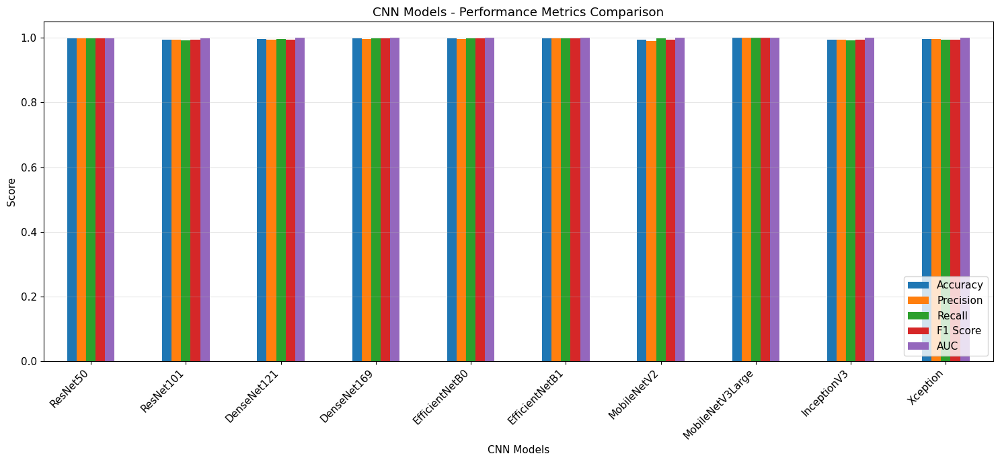

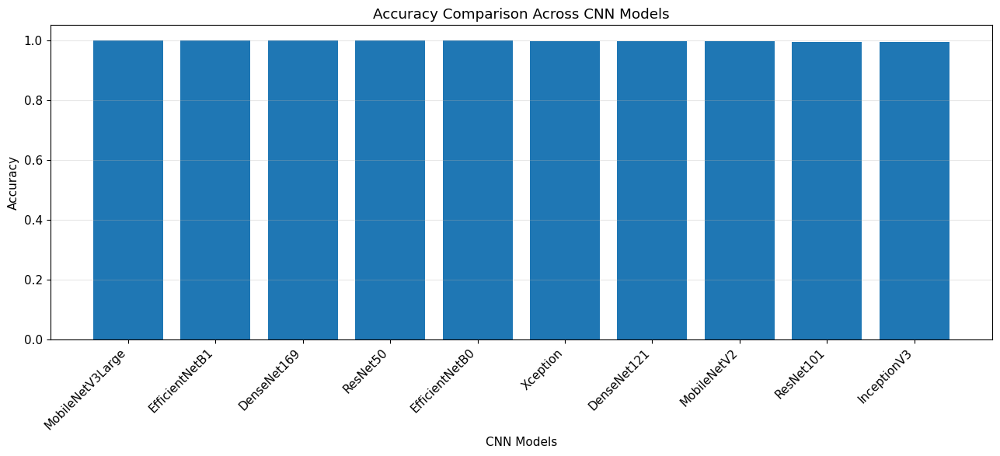

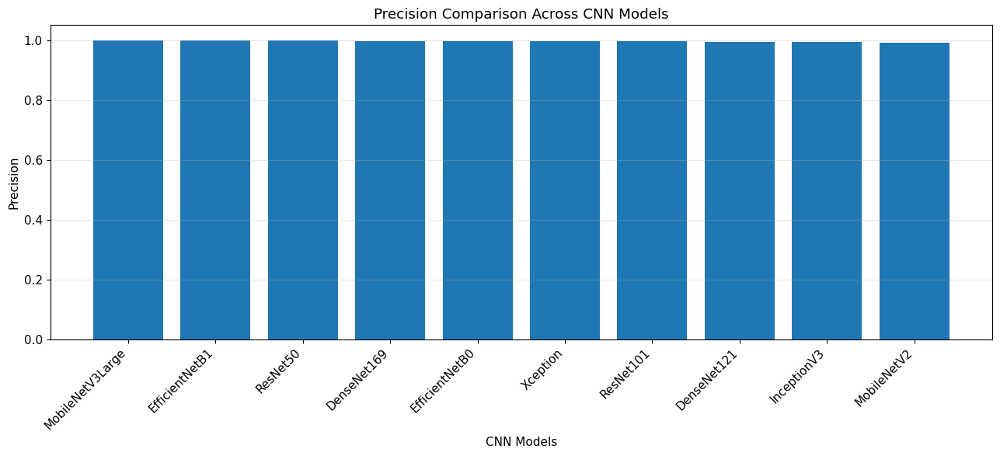

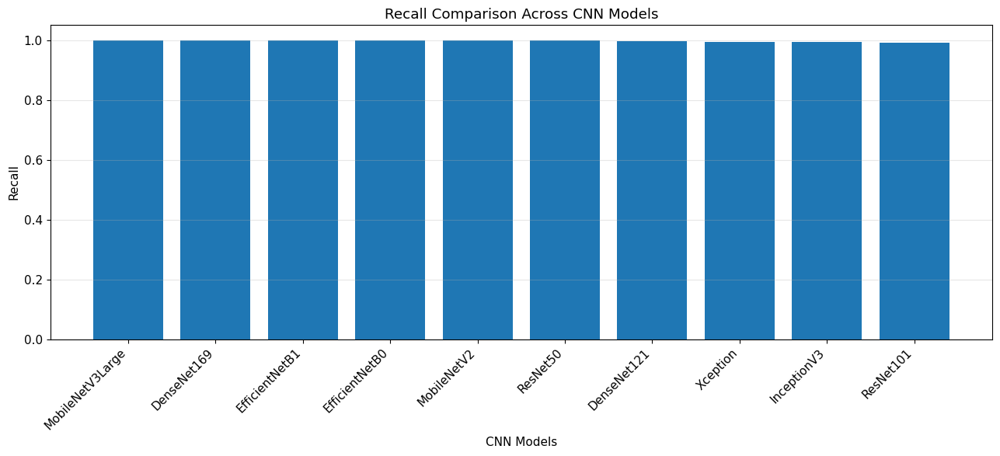

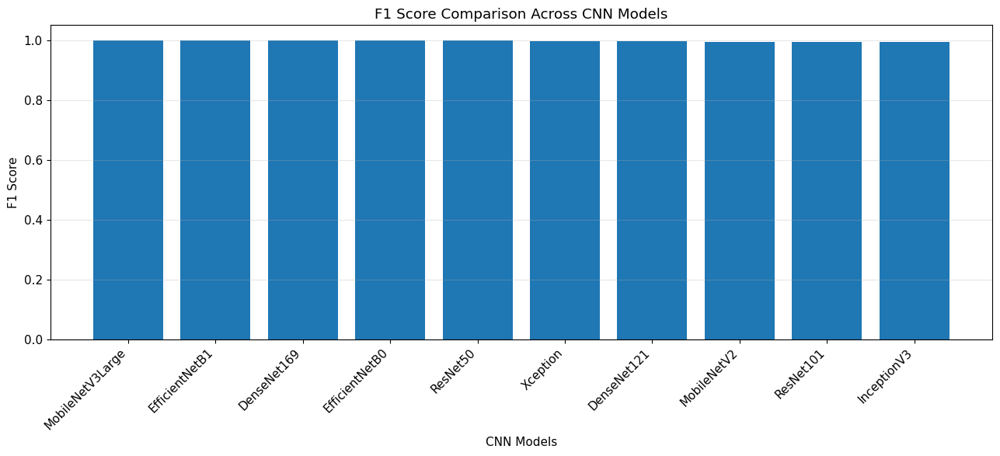

...

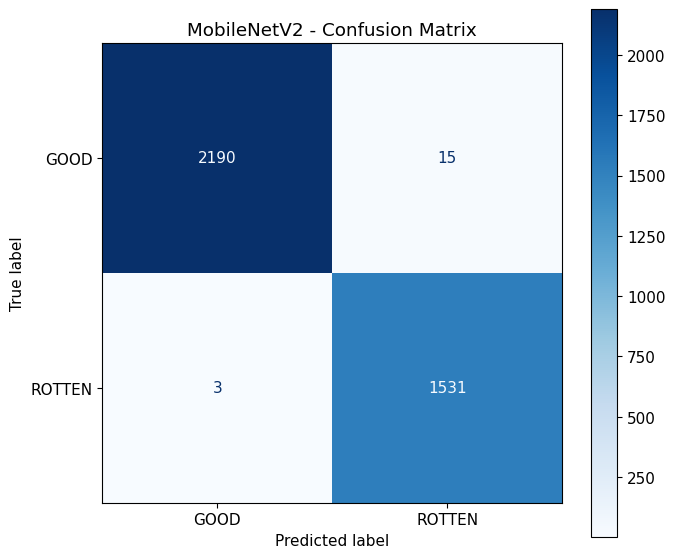

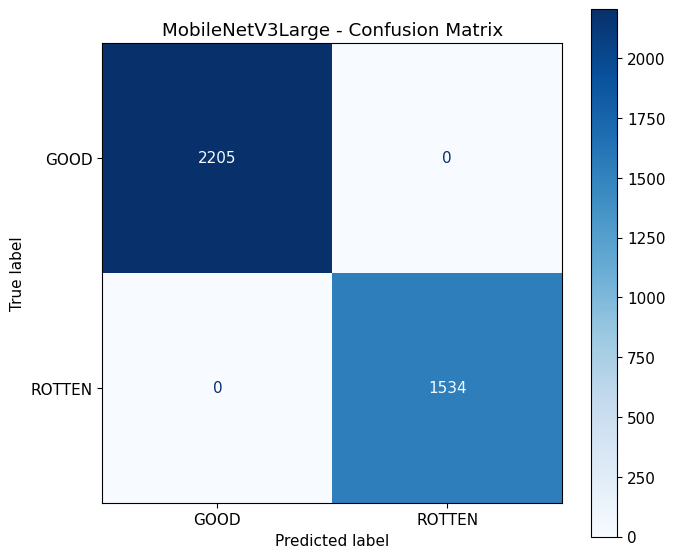

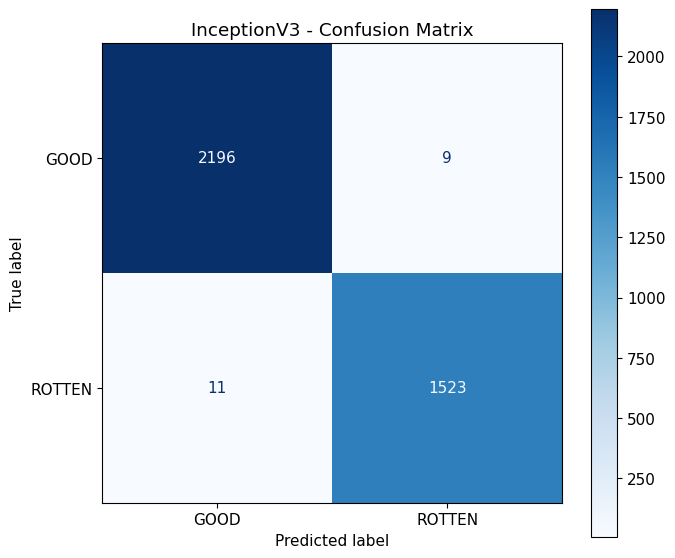

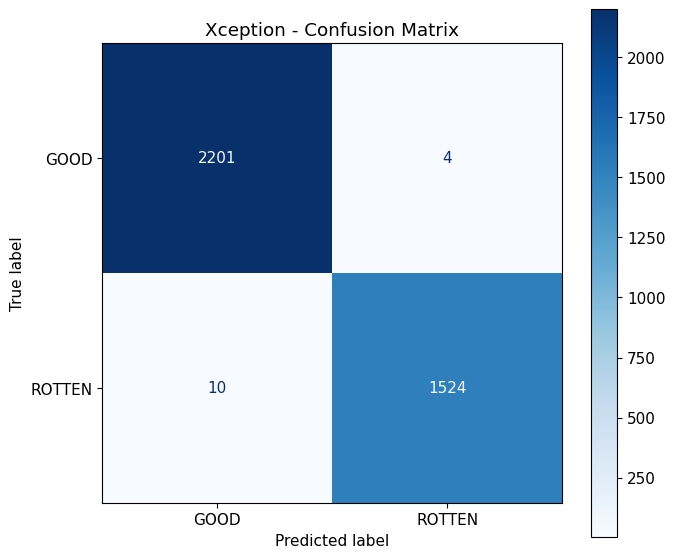

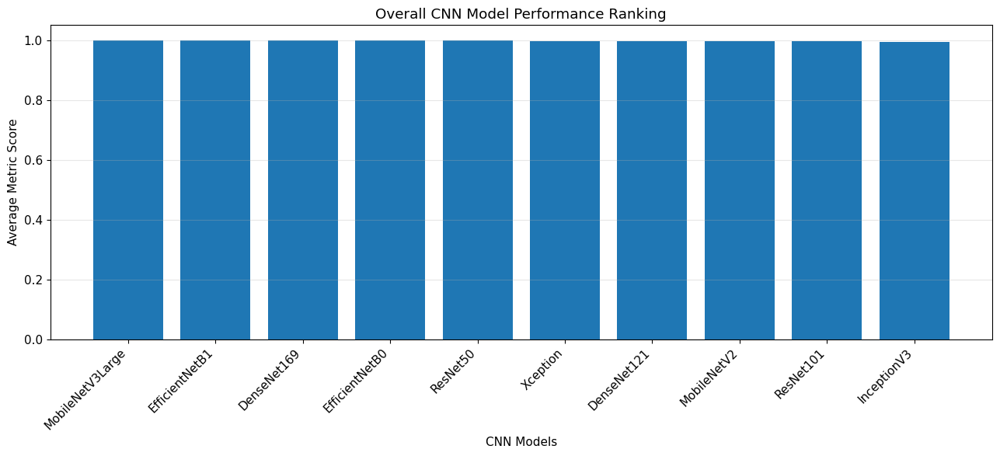


ALL AVAILABLE COMPARISON GRAPHS GENERATED SUCCESSFULLY!

Graphs saved inside:
/content/drive/MyDrive/dataset/results/comparison_graphs

Available graph files:
 - 01_performance_metrics_comparison.png
 - 02_accuracy.png
 - 02_auc.png
 - 02_f1_score.png
 - 02_precision.png
 - 02_recall.png
 - 03_training_time_comparison.png
 - 04_all_models_validation_accuracy.png
 - 05_all_models_validation_loss.png
 - 06_ROC_AUC_all_models.png
 - 07_ROC_AUC_score_comparison.png
 - 08_precision_recall_curves.png
 - 09_average_precision_comparison.png
 - 10_overall_model_ranking.png
 - ROC_AUC_comparison.csv
 - accuracy_DenseNet121.png
 - accuracy_DenseNet169.png
 - accuracy_EfficientNetB0.png
 - accuracy_EfficientNetB1.png
 - accuracy_InceptionV3.png
 - accuracy_MobileNetV2.png
 - accuracy_MobileNetV3Large.png
 - accuracy_ResNet101.png
 - accuracy_ResNet50.png
 - accuracy_Xception.png
 - confusion_matrix_DenseNet121.png
 - confusion_matrix_DenseNet169.png
 - confusion_matrix_EfficientNetB0.png
 - confu

In [ ]:

# ============================================================
# COMPLETE CNN MODEL COMPARISON GRAPH GENERATOR
# Fruit Condition Classification: GOOD vs ROTTEN
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# 1. PATH CONFIGURATION
# ------------------------------------------------------------

RESULTS_PATH = "/content/drive/MyDrive/dataset/results"

COMPARISON_PATH = os.path.join(
    RESULTS_PATH, "model_comparison.csv"
)

HISTORY_PATH = os.path.join(
    RESULTS_PATH, "training_history"
)

PREDICTIONS_PATH = os.path.join(
    RESULTS_PATH, "predictions"
)

GRAPH_PATH = os.path.join(
    RESULTS_PATH, "comparison_graphs"
)

os.makedirs(GRAPH_PATH, exist_ok=True)

# ------------------------------------------------------------
# 2. LOAD MODEL COMPARISON DATA
# ------------------------------------------------------------

if not os.path.exists(COMPARISON_PATH):
    raise FileNotFoundError(
        "model_comparison.csv not found. Run model training first."
    )

comparison_df = pd.read_csv(COMPARISON_PATH)

if comparison_df.empty:
    raise ValueError("The comparison CSV is empty.")

comparison_df = comparison_df.drop_duplicates(
    subset=["Model"], keep="last"
)

print("Models found:")
print(comparison_df["Model"].tolist())

print("\nModel Comparison Table:")
display(comparison_df)

# ------------------------------------------------------------
# 3. COMMON GRAPH SETTINGS
# ------------------------------------------------------------

plt.rcParams["figure.figsize"] = (12, 7)
plt.rcParams["font.size"] = 11

def save_graph(filename):
    plt.tight_layout()
    plt.savefig(
        os.path.join(GRAPH_PATH, filename),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

# ------------------------------------------------------------
# 4. PERFORMANCE METRICS COMPARISON
# ------------------------------------------------------------

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "AUC"
]

available_metrics = [
    metric for metric in metrics
    if metric in comparison_df.columns
]

if available_metrics:
    ax = comparison_df.set_index("Model")[
        available_metrics
    ].plot(kind="bar", figsize=(15, 7))

    ax.set_title("CNN Models - Performance Metrics Comparison")
    ax.set_xlabel("CNN Models")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", alpha=0.3)
    plt.xticks(rotation=45, ha="right")
    plt.legend(loc="lower right")

    save_graph("01_performance_metrics_comparison.png")

# ------------------------------------------------------------
# 5. INDIVIDUAL METRIC COMPARISON GRAPHS
# ------------------------------------------------------------

for metric in available_metrics:

    plt.figure(figsize=(13, 6))

    sorted_df = comparison_df.sort_values(
        by=metric, ascending=False
    )

    plt.bar(
        sorted_df["Model"],
        sorted_df[metric]
    )

    plt.title(f"{metric} Comparison Across CNN Models")
    plt.xlabel("CNN Models")
    plt.ylabel(metric)
    plt.ylim(0, 1.05)
    plt.xticks(rotation=45, ha="right")
    plt.grid(axis="y", alpha=0.3)

    save_graph(f"02_{metric.lower().replace(' ', '_')}.png")

# ------------------------------------------------------------
# 6. TRAINING TIME COMPARISON
# ------------------------------------------------------------

if "Training Time (Minutes)" in comparison_df.columns:

    sorted_time = comparison_df.sort_values(
        "Training Time (Minutes)"
    )

    plt.figure(figsize=(13, 6))

    plt.bar(
        sorted_time["Model"],
        sorted_time["Training Time (Minutes)"]
    )

    plt.title("Training Time Comparison")
    plt.xlabel("CNN Models")
    plt.ylabel("Training Time (Minutes)")
    plt.xticks(rotation=45, ha="right")
    plt.grid(axis="y", alpha=0.3)

    save_graph("03_training_time_comparison.png")

# ------------------------------------------------------------
# 7. TRAINING AND VALIDATION ACCURACY / LOSS
# ------------------------------------------------------------

history_files = [
    f for f in os.listdir(HISTORY_PATH)
    if f.endswith("_history.csv")
] if os.path.exists(HISTORY_PATH) else []

history_models = []

for file in history_files:

    model_name = file.replace("_history.csv", "")

    history_df = pd.read_csv(
        os.path.join(HISTORY_PATH, file)
    )

    history_models.append(model_name)

    # Accuracy graph
    if "accuracy" in history_df.columns:

        plt.figure(figsize=(10, 6))

        plt.plot(
            history_df["accuracy"],
            label="Training Accuracy"
        )

        if "val_accuracy" in history_df.columns:
            plt.plot(
                history_df["val_accuracy"],
                label="Validation Accuracy"
            )

        plt.title(f"{model_name} - Accuracy per Epoch")
        plt.xlabel("Epoch")
        plt.ylabel("Accuracy")
        plt.legend()
        plt.grid(alpha=0.3)

        save_graph(f"accuracy_{model_name}.png")

    # Loss graph
    if "loss" in history_df.columns:

        plt.figure(figsize=(10, 6))

        plt.plot(
            history_df["loss"],
            label="Training Loss"
        )

        if "val_loss" in history_df.columns:
            plt.plot(
                history_df["val_loss"],
                label="Validation Loss"
            )

        plt.title(f"{model_name} - Loss per Epoch")
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.legend()
        plt.grid(alpha=0.3)

        save_graph(f"loss_{model_name}.png")

# Combined validation accuracy
plt.figure(figsize=(14, 7))

for model_name in history_models:

    history_df = pd.read_csv(
        os.path.join(
            HISTORY_PATH,
            f"{model_name}_history.csv"
        )
    )

    if "val_accuracy" in history_df.columns:
        plt.plot(
            range(1, len(history_df) + 1),
            history_df["val_accuracy"],
            marker="o",
            label=model_name
        )

plt.title("All CNN Models - Validation Accuracy per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)

save_graph("04_all_models_validation_accuracy.png")

# Combined validation loss
plt.figure(figsize=(14, 7))

for model_name in history_models:

    history_df = pd.read_csv(
        os.path.join(
            HISTORY_PATH,
            f"{model_name}_history.csv"
        )
    )

    if "val_loss" in history_df.columns:
        plt.plot(
            range(1, len(history_df) + 1),
            history_df["val_loss"],
            marker="o",
            label=model_name
        )

plt.title("All CNN Models - Validation Loss per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)

save_graph("05_all_models_validation_loss.png")

# ------------------------------------------------------------
# 8. ROC CURVES AND ROC-AUC
# ------------------------------------------------------------

plt.figure(figsize=(10, 8))

roc_results = []

for model_name in comparison_df["Model"]:

    prediction_file = os.path.join(
        PREDICTIONS_PATH,
        f"{model_name}_predictions.csv"
    )

    if not os.path.exists(prediction_file):
        print("Missing predictions:", model_name)
        continue

    pred_df = pd.read_csv(prediction_file)

    y_true = pred_df["Actual"].values
    y_prob = pred_df["Probability_ROTTEN"].values

    if len(np.unique(y_true)) < 2:
        print("Cannot calculate ROC for:", model_name)
        continue

    fpr, tpr, thresholds = roc_curve(y_true, y_prob)
    roc_auc = auc(fpr, tpr)

    roc_results.append({
        "Model": model_name,
        "ROC-AUC": roc_auc
    })

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUC = {roc_auc:.4f})"
    )

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison - All CNN Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)

save_graph("06_ROC_AUC_all_models.png")

# Save ROC-AUC comparison
if roc_results:

    roc_df = pd.DataFrame(roc_results).sort_values(
        "ROC-AUC", ascending=False
    )

    roc_df.to_csv(
        os.path.join(GRAPH_PATH, "ROC_AUC_comparison.csv"),
        index=False
    )

    plt.figure(figsize=(13, 6))

    plt.bar(
        roc_df["Model"],
        roc_df["ROC-AUC"]
    )

    plt.title("ROC-AUC Score Comparison")
    plt.xlabel("CNN Models")
    plt.ylabel("ROC-AUC")
    plt.ylim(0, 1.05)
    plt.xticks(rotation=45, ha="right")
    plt.grid(axis="y", alpha=0.3)

    save_graph("07_ROC_AUC_score_comparison.png")

# ------------------------------------------------------------
# 9. PRECISION-RECALL CURVES
# ------------------------------------------------------------

plt.figure(figsize=(10, 8))

pr_results = []

for model_name in comparison_df["Model"]:

    prediction_file = os.path.join(
        PREDICTIONS_PATH,
        f"{model_name}_predictions.csv"
    )

    if not os.path.exists(prediction_file):
        continue

    pred_df = pd.read_csv(prediction_file)

    y_true = pred_df["Actual"].values
    y_prob = pred_df["Probability_ROTTEN"].values

    if len(np.unique(y_true)) < 2:
        continue

    precision_curve, recall_curve, _ = precision_recall_curve(
        y_true, y_prob
    )

    ap = average_precision_score(y_true, y_prob)

    pr_results.append({
        "Model": model_name,
        "Average Precision": ap
    })

    plt.plot(
        recall_curve,
        precision_curve,
        linewidth=2,
        label=f"{model_name} (AP = {ap:.4f})"
    )

plt.title("Precision-Recall Curve Comparison")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)

save_graph("08_precision_recall_curves.png")

if pr_results:

    pr_df = pd.DataFrame(pr_results).sort_values(
        "Average Precision", ascending=False
    )

    pr_df.to_csv(
        os.path.join(
            GRAPH_PATH,
            "precision_recall_comparison.csv"
        ),
        index=False
    )

    plt.figure(figsize=(13, 6))

    plt.bar(
        pr_df["Model"],
        pr_df["Average Precision"]
    )

    plt.title("Average Precision Comparison")
    plt.xlabel("CNN Models")
    plt.ylabel("Average Precision")
    plt.ylim(0, 1.05)
    plt.xticks(rotation=45, ha="right")
    plt.grid(axis="y", alpha=0.3)

    save_graph("09_average_precision_comparison.png")

# ------------------------------------------------------------
# 10. CONFUSION MATRICES FOR ALL MODELS
# ------------------------------------------------------------

for model_name in comparison_df["Model"]:

    prediction_file = os.path.join(
        PREDICTIONS_PATH,
        f"{model_name}_predictions.csv"
    )

    if not os.path.exists(prediction_file):
        continue

    pred_df = pd.read_csv(prediction_file)

    y_true = pred_df["Actual"].values
    y_pred = pred_df["Predicted"].values

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    fig, ax = plt.subplots(figsize=(7, 6))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["GOOD", "ROTTEN"]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=True
    )

    plt.title(f"{model_name} - Confusion Matrix")

    save_graph(f"confusion_matrix_{model_name}.png")

# ------------------------------------------------------------
# 11. MODEL PERFORMANCE RANKING
# ------------------------------------------------------------

ranking_metrics = [
    metric for metric in
    ["Accuracy", "Precision", "Recall", "F1 Score", "AUC"]
    if metric in comparison_df.columns
]

if ranking_metrics:

    comparison_df["Overall Score"] = (
        comparison_df[ranking_metrics]
        .mean(axis=1)
    )

    ranking_df = comparison_df.sort_values(
        "Overall Score",
        ascending=False
    )

    ranking_df.to_csv(
        os.path.join(GRAPH_PATH, "model_performance_ranking.csv"),
        index=False
    )

    plt.figure(figsize=(13, 6))

    plt.bar(
        ranking_df["Model"],
        ranking_df["Overall Score"]
    )

    plt.title("Overall CNN Model Performance Ranking")
    plt.xlabel("CNN Models")
    plt.ylabel("Average Metric Score")
    plt.ylim(0, 1.05)
    plt.xticks(rotation=45, ha="right")
    plt.grid(axis="y", alpha=0.3)

    save_graph("10_overall_model_ranking.png")

# ------------------------------------------------------------
# 12. FINAL OUTPUT
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("ALL AVAILABLE COMPARISON GRAPHS GENERATED SUCCESSFULLY!")
print("=" * 60)

print("\nGraphs saved inside:")
print(GRAPH_PATH)

print("\nAvailable graph files:")

for filename in sorted(os.listdir(GRAPH_PATH)):
    print(" -", filename)


TensorFlow Version: 2.21.0
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Total Test Images: 3739

First 20 Available Images:
0 : /content/drive/MyDrive/dataset/dataset/test/freshapples/Screen Shot 2018-06-08 at 4.59.44 PM.png
1 : /content/drive/MyDrive/dataset/dataset/test/freshapples/Screen Shot 2018-06-08 at 5.01.15 PM.png
2 : /content/drive/MyDrive/dataset/dataset/test/freshapples/Screen Shot 2018-06-08 at 5.01.22 PM.png
3 : /content/drive/MyDrive/dataset/dataset/test/freshapples/Screen Shot 2018-06-08 at 5.01.41 PM.png
4 : /content/drive/MyDrive/dataset/dataset/test/freshapples/Screen Shot 2018-06-08 at 5.02.43 PM.png
5 : /content/drive/MyDrive/dataset/dataset/test/freshapples/Screen Shot 2018-06-08 at 5.03.40 PM.png
6 : /content/drive/MyDrive/dataset/dataset/test/freshapples/Screen Shot 2018-06-08 at 5.04.16 PM.png
7 : /content/drive/MyDrive/dataset/dataset/test/freshapples/Screen Shot 2018-06-08 a

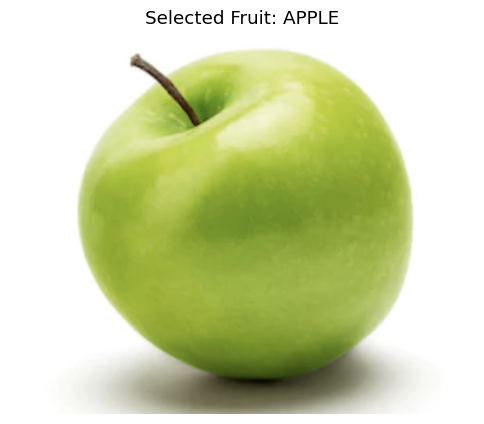



STARTING PREDICTION USING 10 CNN MODELS


-----------------------------------------------------------------
MODEL: ResNet50
-----------------------------------------------------------------
Loading: /content/drive/MyDrive/dataset/results/saved_models/ResNet50.keras



Fruit: APPLE
Prediction: GOOD
Final Label: Fresh Apple
GOOD Probability: 100.0 %
ROTTEN Probability: 0.0 %
Confidence: 100.0 %


-----------------------------------------------------------------
MODEL: ResNet101
-----------------------------------------------------------------
Loading: /content/drive/MyDrive/dataset/results/saved_models/ResNet101.keras



Fruit: APPLE
Prediction: GOOD
Final Label: Fresh Apple
GOOD Probability: 100.0 %
ROTTEN Probability: 0.0 %
Confidence: 100.0 %


-----------------------------------------------------------------
MODEL: DenseNet121
-----------------------------------------------------------------
Loading: /content/drive/MyDrive/dataset/results/saved_models/DenseNet121.keras

Fruit: APPLE
Prediction: GOOD
Final Label: Fresh Apple
GOOD Probability: 100.0 %
ROTTEN Probability: 0.0 %
Confidence: 100.0 %


-----------------------------------------------------------------
MODEL: DenseNet169
-----------------------------------------------------------------
Loading: /content/drive/MyDrive/dataset/results/saved_models/DenseNet169.keras

Fruit: APPLE
Prediction: GOOD
Final Label: Fresh Apple
GOOD Probability: 100.0 %
ROTTEN Probability: 0.0 %
Confidence: 100.0 %


-----------------------------------------------------------------
MODEL: EfficientNetB0
--------------------------------------------------------------

,Model,Fruit,Prediction,Final Label,Confidence (%),GOOD Probability (%),ROTTEN Probability (%),Model File,Status
0,ResNet50,APPLE,GOOD,Fresh Apple,100.00,100.00,0.00,ResNet50.keras,SUCCESS
1,ResNet101,APPLE,GOOD,Fresh Apple,100.00,100.00,0.00,ResNet101.keras,SUCCESS
2,DenseNet121,APPLE,GOOD,Fresh Apple,100.00,100.00,0.00,DenseNet121.keras,SUCCESS
3,DenseNet169,APPLE,GOOD,Fresh Apple,100.00,100.00,0.00,DenseNet169.keras,SUCCESS
4,EfficientNetB0,APPLE,GOOD,Fresh Apple,100.00,100.00,0.00,EfficientNetB0.keras,SUCCESS
5,EfficientNetB1,APPLE,GOOD,Fresh Apple,100.00,100.00,0.00,EfficientNetB1.keras,SUCCESS
6,MobileNetV2,APPLE,GOOD,Fresh Apple,100.00,100.00,0.00,MobileNetV2.keras,SUCCESS
7,MobileNetV3Large,APPLE,GOOD,Fresh Apple,100.00,100.00,0.00,MobileNetV3Large.keras,SUCCESS
8,InceptionV3,APPLE,GOOD,Fresh Apple,99.97,99.97,0.03,InceptionV3.keras,SUCCESS
9,Xception,APPLE,GOOD,Fresh Apple,99.99,99.99,0.01,Xception.keras,SUCCESS




FINAL MAJORITY VOTING
Fruit: APPLE
GOOD Votes: 10
ROTTEN Votes: 0
Total Successful Models: 10
Final Prediction: GOOD

FINAL RESULT: FRESH Apple


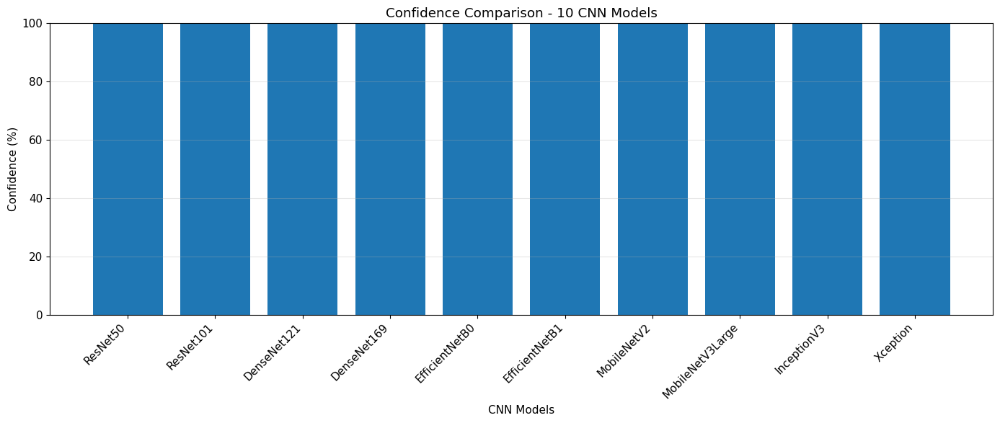

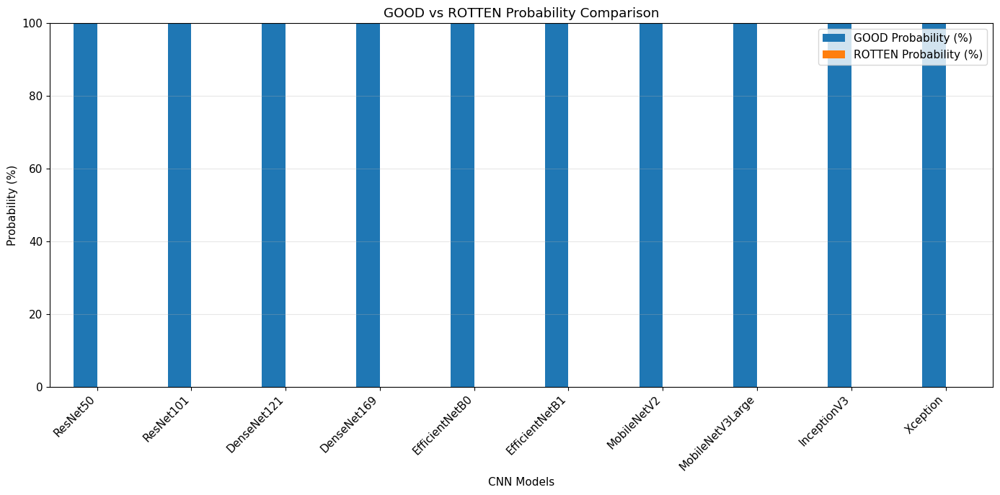



PREDICTION PROCESS COMPLETED
Total Models: 10
Successful Models: 10
Failed Models: 0

Results Saved At:
/content/drive/MyDrive/dataset/results/predictions/Screen Shot 2018-06-08 at 4.59.44 PM_all_model_predictions.csv

AIDL PROJECT - FRUIT FRESHNESS CLASSIFICATION


In [ ]:

# ================================================================
# AIDL PROJECT - COMPLETE FRUIT IMAGE PREDICTION
# 10 CNN MODELS | GOOGLE DRIVE | TENSORFLOW 2.21
# ================================================================

import os
import re
import gc
import glob
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display

from tensorflow.keras import layers, models

from tensorflow.keras.applications import (
    ResNet50, ResNet101,
    DenseNet121, DenseNet169,
    EfficientNetB0, EfficientNetB1,
    MobileNetV2, MobileNetV3Large,
    InceptionV3, Xception
)

# Preprocessing functions
from tensorflow.keras.applications.resnet import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.applications.inception_v3 import preprocess_input as inception_preprocess
from tensorflow.keras.applications.xception import preprocess_input as xception_preprocess


print("TensorFlow Version:", tf.__version__)


# ================================================================
# 1. GOOGLE DRIVE
# ================================================================

from google.colab import drive

drive.mount('/content/drive')

BASE_PATH = "/content/drive/MyDrive/dataset"

TEST_PATH = os.path.join(
    BASE_PATH, "dataset", "test"
)

RESULTS_PATH = os.path.join(
    BASE_PATH, "results"
)

SAVED_MODELS_PATH = os.path.join(
    RESULTS_PATH, "saved_models"
)

WEIGHTS_PATH = os.path.join(
    RESULTS_PATH, "model_weights"
)

PREDICTIONS_PATH = os.path.join(
    RESULTS_PATH, "predictions"
)

os.makedirs(
    PREDICTIONS_PATH,
    exist_ok=True
)


# ================================================================
# 2. MODEL CONFIGURATION
# EXACT CONFIGURATION FROM TRAINING NOTEBOOK
# ================================================================

MODEL_CONFIGS = {

    "ResNet50": {
        "size": 224,
        "constructor": ResNet50,
        "preprocessing": "resnet"
    },

    "ResNet101": {
        "size": 224,
        "constructor": ResNet101,
        "preprocessing": "resnet"
    },

    "DenseNet121": {
        "size": 224,
        "constructor": DenseNet121,
        "preprocessing": "densenet"
    },

    "DenseNet169": {
        "size": 224,
        "constructor": DenseNet169,
        "preprocessing": "densenet"
    },

    "EfficientNetB0": {
        "size": 224,
        "constructor": EfficientNetB0,
        "preprocessing": "efficientnet"
    },

    "EfficientNetB1": {
        "size": 240,
        "constructor": EfficientNetB1,
        "preprocessing": "efficientnet"
    },

    "MobileNetV2": {
        "size": 224,
        "constructor": MobileNetV2,
        "preprocessing": "mobilenet"
    },

    "MobileNetV3Large": {
        "size": 224,
        "constructor": MobileNetV3Large,
        "preprocessing": "mobilenetv3"
    },

    "InceptionV3": {
        "size": 299,
        "constructor": InceptionV3,
        "preprocessing": "inception"
    },

    "Xception": {
        "size": 299,
        "constructor": Xception,
        "preprocessing": "xception"
    }
}

MODEL_NAMES = list(MODEL_CONFIGS.keys())


# ================================================================
# 3. PREPROCESSING FUNCTION MAPPING
# IMPORTANT FIX FOR KERAS MODEL DESERIALIZATION
# ================================================================

PREPROCESSING_FUNCTIONS = {

    "resnet": resnet_preprocess,

    "densenet": densenet_preprocess,

    "mobilenet": mobilenet_preprocess,

    "inception": inception_preprocess,

    "xception": xception_preprocess,

    "efficientnet": None,

    "mobilenetv3": None
}


def get_custom_objects(model_name):

    preprocessing = MODEL_CONFIGS[
        model_name
    ]["preprocessing"]

    function = PREPROCESSING_FUNCTIONS[
        preprocessing
    ]

    if function is None:
        return {}

    return {
        "preprocess_input": function
    }


# ================================================================
# 4. BUILD MODEL
# EXACT MATCH WITH YOUR ORIGINAL TRAINING NOTEBOOK
# ================================================================

def build_model(model_name):

    config = MODEL_CONFIGS[model_name]

    input_size = config["size"]

    constructor = config["constructor"]

    inputs = layers.Input(
        shape=(input_size, input_size, 3),
        name="input_image"
    )

    backbone_arguments = {
        "include_top": False,
        "weights": "imagenet",
        "input_shape": (input_size, input_size, 3)
    }

    if model_name == "MobileNetV3Large":

        backbone_arguments["include_preprocessing"] = True

    backbone = constructor(
        **backbone_arguments
    )

    backbone.trainable = False

    preprocessing = config["preprocessing"]

    if preprocessing in [
        "resnet",
        "densenet",
        "mobilenet",
        "inception",
        "xception"
    ]:

        x = layers.Lambda(
            PREPROCESSING_FUNCTIONS[preprocessing]
        )(inputs)

    else:

        x = inputs

    x = backbone(
        x,
        training=False
    )

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(
        256,
        activation="relu"
    )(x)

    x = layers.Dropout(0.4)(x)

    outputs = layers.Dense(
        1,
        activation="sigmoid"
    )(x)

    model = models.Model(
        inputs=inputs,
        outputs=outputs,
        name=model_name
    )

    return model, backbone


# ================================================================
# 5. FRUIT FOLDER MAPPING
# ================================================================

FRUIT_MAPPING = {

    "freshapples": "APPLE",
    "rottenapples": "APPLE",

    "freshbanana": "BANANA",
    "freshbananas": "BANANA",
    "rottenbanana": "BANANA",
    "rottenbananas": "BANANA",

    "freshoranges": "ORANGE",
    "rottenoranges": "ORANGE"
}

CONDITION_MAPPING = {

    "freshapples": "GOOD",
    "freshbanana": "GOOD",
    "freshbananas": "GOOD",
    "freshoranges": "GOOD",

    "rottenapples": "ROTTEN",
    "rottenbanana": "ROTTEN",
    "rottenbananas": "ROTTEN",
    "rottenoranges": "ROTTEN"
}


# ================================================================
# 6. AUTOMATICALLY FIND TEST IMAGES
# ================================================================

if not os.path.isdir(TEST_PATH):

    raise FileNotFoundError(
        "Test directory not found: " + TEST_PATH
    )

IMAGE_EXTENSIONS = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
)

image_files = []

for root, dirs, files in os.walk(TEST_PATH):

    for filename in files:

        if filename.lower().endswith(IMAGE_EXTENSIONS):

            image_files.append(
                os.path.join(root, filename)
            )

image_files.sort()

print("\nTotal Test Images:", len(image_files))

if len(image_files) == 0:

    raise ValueError(
        "No test images found!"
    )

print("\nFirst 20 Available Images:")

for i, path in enumerate(image_files[:20]):

    print(i, ":", path)


# ================================================================
# 7. SELECT IMAGE
# ================================================================

IMAGE_INDEX = 0

if not 0 <= IMAGE_INDEX < len(image_files):

    raise IndexError(
        "Invalid image index!"
    )

IMAGE_PATH = image_files[IMAGE_INDEX]

original_image = Image.open(
    IMAGE_PATH
).convert("RGB")

folder_name = os.path.basename(
    os.path.dirname(IMAGE_PATH)
).strip().lower()

fruit_name = FRUIT_MAPPING.get(
    folder_name,
    "UNKNOWN"
)

actual_condition = CONDITION_MAPPING.get(
    folder_name,
    "UNKNOWN"
)

print("\nSelected Image:", IMAGE_PATH)

print("Fruit Category:", fruit_name)

print("Folder Label:", actual_condition)

plt.figure(figsize=(6, 6))

plt.imshow(original_image)

plt.title(
    "Selected Fruit: " + fruit_name
)

plt.axis("off")

plt.show()


# ================================================================
# 8. FIND SAVED MODEL FILES
# ================================================================

def find_model_file(model_name):

    keras_path = os.path.join(
        SAVED_MODELS_PATH,
        model_name + ".keras"
    )

    if os.path.exists(keras_path):

        return keras_path

    pattern = os.path.join(
        WEIGHTS_PATH,
        model_name + "_epoch*.weights.h5"
    )

    files = glob.glob(pattern)

    if files:

        def epoch_number(path):

            match = re.search(
                r"_epoch(\d+)\.weights\.h5$",
                os.path.basename(path)
            )

            return int(match.group(1)) if match else -1

        files.sort(
            key=epoch_number
        )

        return files[-1]

    return None


# ================================================================
# 9. LOAD MODELS WITH CUSTOM PREPROCESSING
# ================================================================

def load_trained_model(model_name):

    model_path = find_model_file(model_name)

    if model_path is None:

        raise FileNotFoundError(
            "Saved model not found for " + model_name
        )

    print("Loading:", model_path)

    if model_path.endswith(".keras"):

        custom_objects = get_custom_objects(
            model_name
        )

        model = tf.keras.models.load_model(

            model_path,

            custom_objects=custom_objects,

            compile=False,

            safe_mode=False

        )

    else:

        model, backbone = build_model(
            model_name
        )

        model.load_weights(
            model_path
        )

    return model, model_path


# ================================================================
# 10. IMAGE PREDICTION FUNCTION
# ================================================================

def predict_image(model, model_name, image):

    image_size = MODEL_CONFIGS[
        model_name
    ]["size"]

    resized_image = image.resize(
        (image_size, image_size)
    )

    image_array = np.asarray(
        resized_image,
        dtype=np.float32
    )

    image_array = np.expand_dims(
        image_array,
        axis=0
    )

    prediction = model.predict(
        image_array,
        verbose=0
    )

    rotten_probability = float(
        prediction[0][0]
    )

    good_probability = (
        1.0 - rotten_probability
    )

    if rotten_probability >= 0.5:

        predicted_condition = "ROTTEN"

        confidence = rotten_probability * 100

    else:

        predicted_condition = "GOOD"

        confidence = good_probability * 100

    return (
        predicted_condition,
        confidence,
        good_probability * 100,
        rotten_probability * 100
    )


# ================================================================
# 11. RUN ALL 10 MODELS
# ================================================================

all_results = []

print("\n")
print("=" * 75)
print("STARTING PREDICTION USING 10 CNN MODELS")
print("=" * 75)

for model_name in MODEL_NAMES:

    print("\n")
    print("-" * 65)
    print("MODEL:", model_name)
    print("-" * 65)

    tf.keras.backend.clear_session()
    gc.collect()

    try:

        # Load trained model
        model, model_path = load_trained_model(
            model_name
        )

        # Predict selected image
        (
            predicted_condition,
            confidence,
            good_probability,
            rotten_probability
        ) = predict_image(
            model,
            model_name,
            original_image
        )

        if fruit_name != "UNKNOWN":

            final_label = (
                "Fresh " if predicted_condition == "GOOD"
                else "Rotten "
            ) + fruit_name.title()

        else:

            final_label = predicted_condition

        print("\nFruit:", fruit_name)

        print("Prediction:", predicted_condition)

        print("Final Label:", final_label)

        print(
            "GOOD Probability:",
            round(good_probability, 2),
            "%"
        )

        print(
            "ROTTEN Probability:",
            round(rotten_probability, 2),
            "%"
        )

        print(
            "Confidence:",
            round(confidence, 2),
            "%"
        )

        all_results.append({

            "Model": model_name,

            "Fruit": fruit_name,

            "Prediction": predicted_condition,

            "Final Label": final_label,

            "Confidence (%)": round(confidence, 2),

            "GOOD Probability (%)": round(
                good_probability, 2
            ),

            "ROTTEN Probability (%)": round(
                rotten_probability, 2
            ),

            "Model File": os.path.basename(model_path),

            "Status": "SUCCESS"

        })

        del model

    except Exception as e:

        print("\nMODEL ERROR:", str(e))

        all_results.append({

            "Model": model_name,

            "Fruit": fruit_name,

            "Prediction": "ERROR",

            "Final Label": "ERROR",

            "Confidence (%)": 0,

            "GOOD Probability (%)": 0,

            "ROTTEN Probability (%)": 0,

            "Model File": "ERROR",

            "Status": "FAILED"

        })

    gc.collect()


# ================================================================
# 12. DISPLAY MODEL COMPARISON TABLE
# ================================================================

results_df = pd.DataFrame(
    all_results
)

print("\n")
print("=" * 85)
print("ALL 10 CNN MODEL PREDICTION RESULTS")
print("=" * 85)

display(results_df)


# ================================================================
# 13. MAJORITY VOTING
# ================================================================

valid_results = results_df[
    results_df["Status"] == "SUCCESS"
]

if len(valid_results) > 0:

    good_votes = int(
        (
            valid_results["Prediction"] == "GOOD"
        ).sum()
    )

    rotten_votes = int(
        (
            valid_results["Prediction"] == "ROTTEN"
        ).sum()
    )

    if good_votes > rotten_votes:

        final_prediction = "GOOD"

    elif rotten_votes > good_votes:

        final_prediction = "ROTTEN"

    else:

        final_prediction = "TIE"

    print("\n")
    print("=" * 65)
    print("FINAL MAJORITY VOTING")
    print("=" * 65)

    print("Fruit:", fruit_name)

    print("GOOD Votes:", good_votes)

    print("ROTTEN Votes:", rotten_votes)

    print("Total Successful Models:", len(valid_results))

    print("Final Prediction:", final_prediction)

    if fruit_name != "UNKNOWN" and final_prediction != "TIE":

        if final_prediction == "GOOD":

            print(
                "\nFINAL RESULT: FRESH",
                fruit_name.title()
            )

        else:

            print(
                "\nFINAL RESULT: ROTTEN",
                fruit_name.title()
            )

else:

    print("No models successfully predicted the image.")


# ================================================================
# 14. CONFIDENCE COMPARISON GRAPH
# ================================================================

if len(valid_results) > 0:

    plt.figure(figsize=(14, 6))

    plt.bar(
        valid_results["Model"],
        valid_results["Confidence (%)"]
    )

    plt.title(
        "Confidence Comparison - 10 CNN Models"
    )

    plt.xlabel("CNN Models")

    plt.ylabel("Confidence (%)")

    plt.ylim(0, 100)

    plt.xticks(
        rotation=45,
        ha="right"
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


# ================================================================
# 15. GOOD VS ROTTEN PROBABILITY GRAPH
# ================================================================

if len(valid_results) > 0:

    graph_df = valid_results.set_index(
        "Model"
    )[
        [
            "GOOD Probability (%)",
            "ROTTEN Probability (%)"
        ]
    ]

    graph_df.plot(
        kind="bar",
        figsize=(14, 7)
    )

    plt.title(
        "GOOD vs ROTTEN Probability Comparison"
    )

    plt.xlabel("CNN Models")

    plt.ylabel("Probability (%)")

    plt.ylim(0, 100)

    plt.xticks(
        rotation=45,
        ha="right"
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


# ================================================================
# 16. SAVE PREDICTION RESULTS
# ================================================================

image_name = os.path.splitext(
    os.path.basename(IMAGE_PATH)
)[0]

csv_path = os.path.join(
    PREDICTIONS_PATH,
    image_name + "_all_model_predictions.csv"
)

results_df.to_csv(
    csv_path,
    index=False
)

print("\n")
print("=" * 75)
print("PREDICTION PROCESS COMPLETED")
print("=" * 75)

print("Total Models:", len(MODEL_NAMES))

print("Successful Models:", len(valid_results))

print(
    "Failed Models:",
    len(MODEL_NAMES) - len(valid_results)
)

print("\nResults Saved At:")

print(csv_path)

print("\nAIDL PROJECT - FRUIT FRESHNESS CLASSIFICATION")


TensorFlow Version: 2.21.0
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Test Folder: /content/drive/MyDrive/dataset/dataset/test
Saved Models: /content/drive/MyDrive/dataset/results/saved_models
Output Folder: /content/drive/MyDrive/dataset/results/predictions/visual_predictions

SELECTING SIX TEST IMAGES
Fresh Apple -> translation_Screen Shot 2018-06-08 at 5.15.39 PM.png
Rotten Apple -> rotated_by_15_Screen Shot 2018-06-07 at 3.00.00 PM.png
Fresh Banana -> Screen Shot 2018-06-12 at 9.39.13 PM.png
Rotten Banana -> rotated_by_75_Screen Shot 2018-06-12 at 8.47.41 PM.png
Fresh Orange -> rotated_by_45_Screen Shot 2018-06-12 at 11.52.26 PM.png
Rotten Orange -> rotated_by_30_Screen Shot 2018-06-12 at 11.40.23 PM.png

Total Selected Images: 6


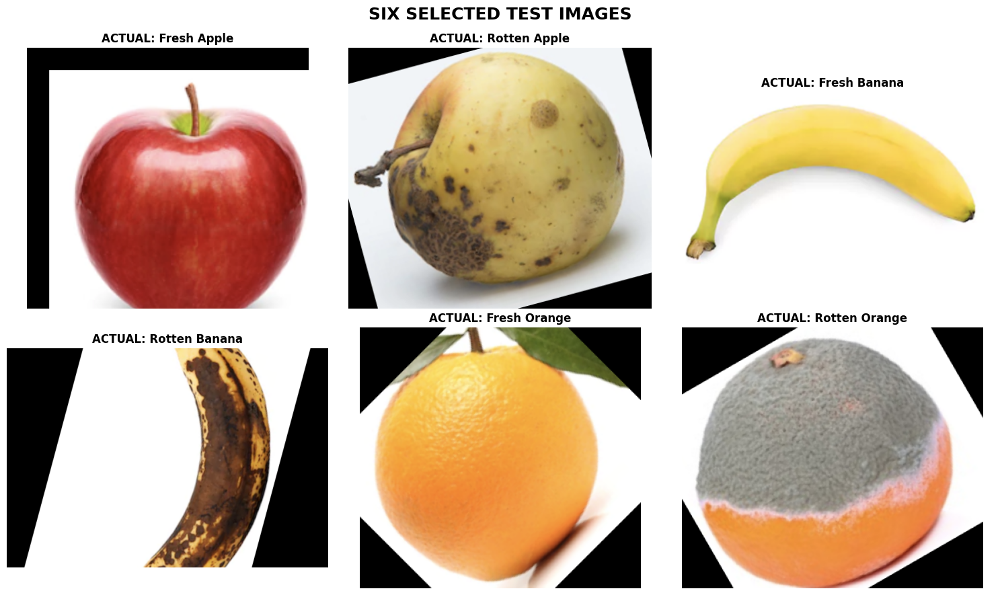



STARTING VISUAL PREDICTION
10 MODELS x 6 IMAGES = 60 PREDICTIONS


###########################################################################
MODEL 1/10: ResNet50
###########################################################################

Predicting: Fresh Apple
Actual: Fresh Apple
Predicted: Fresh Apple
Confidence: 99.93 %
Result: CORRECT

Predicting: Rotten Apple
Actual: Rotten Apple
Predicted: Rotten Apple
Confidence: 100.0 %
Result: CORRECT

Predicting: Fresh Banana
Actual: Fresh Banana
Predicted: Fresh Banana
Confidence: 100.0 %
Result: CORRECT

Predicting: Rotten Banana
Actual: Rotten Banana
Predicted: Rotten Banana
Confidence: 100.0 %
Result: CORRECT

Predicting: Fresh Orange
Actual: Fresh Orange
Predicted: Fresh Orange
Confidence: 100.0 %
Result: CORRECT

Predicting: Rotten Orange
Actual: Rotten Orange
Predicted: Rotten Orange
Confidence: 100.0 %
Result: CORRECT


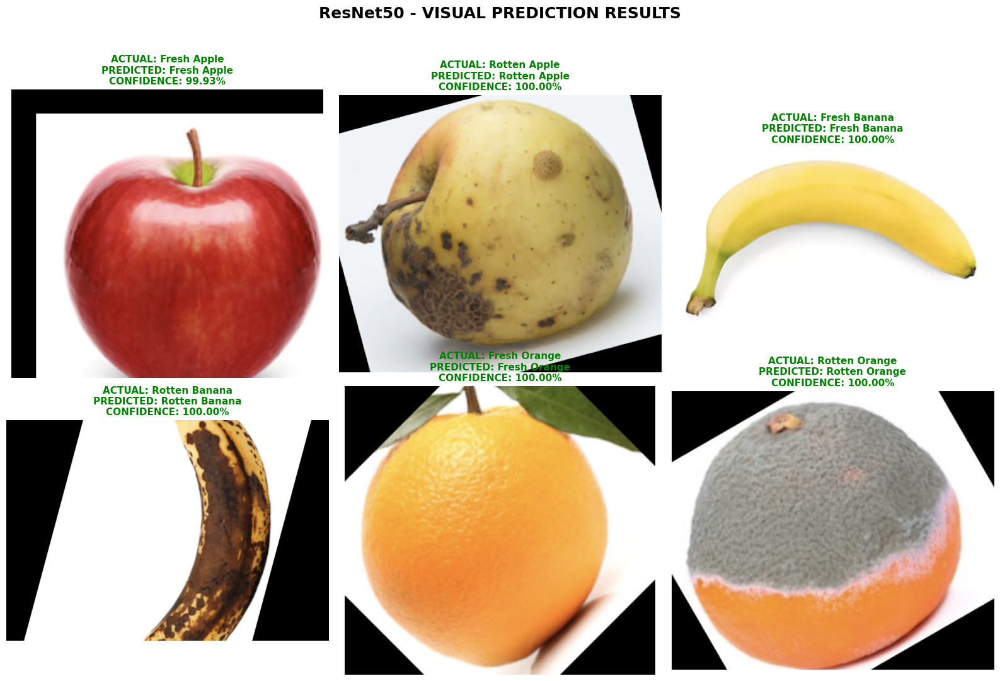


Visual output saved: /content/drive/MyDrive/dataset/results/predictions/visual_predictions/ResNet50_visual_predictions.png


###########################################################################
MODEL 2/10: ResNet101
###########################################################################

Predicting: Fresh Apple
Actual: Fresh Apple
Predicted: Fresh Apple
Confidence: 99.99 %
Result: CORRECT

Predicting: Rotten Apple
Actual: Rotten Apple
Predicted: Rotten Apple
Confidence: 100.0 %
Result: CORRECT

Predicting: Fresh Banana
Actual: Fresh Banana
Predicted: Fresh Banana
Confidence: 100.0 %
Result: CORRECT

Predicting: Rotten Banana
Actual: Rotten Banana
Predicted: Rotten Banana
Confidence: 100.0 %
Result: CORRECT

Predicting: Fresh Orange
Actual: Fresh Orange
Predicted: Fresh Orange
Confidence: 100.0 %
Result: CORRECT

Predicting: Rotten Orange
Actual: Rotten Orange
Predicted: Rotten Orange
Confidence: 100.0 %
Result: CORRECT


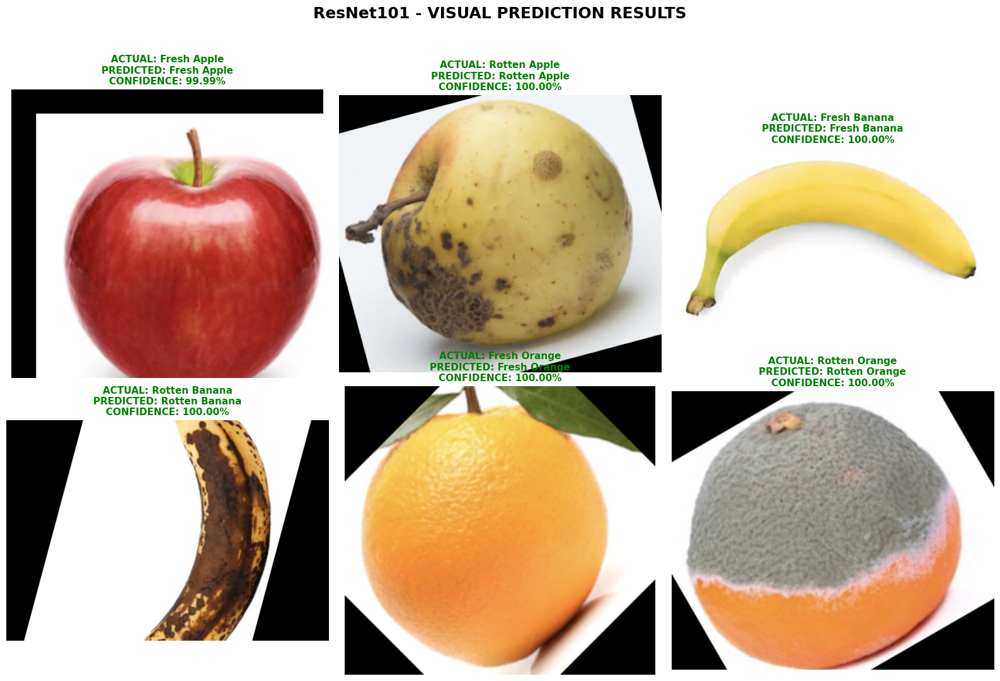


Visual output saved: /content/drive/MyDrive/dataset/results/predictions/visual_predictions/ResNet101_visual_predictions.png


###########################################################################
MODEL 3/10: DenseNet121
###########################################################################

Predicting: Fresh Apple
Actual: Fresh Apple
Predicted: Fresh Apple
Confidence: 99.99 %
Result: CORRECT

Predicting: Rotten Apple
Actual: Rotten Apple
Predicted: Rotten Apple
Confidence: 100.0 %
Result: CORRECT

Predicting: Fresh Banana
Actual: Fresh Banana
Predicted: Fresh Banana
Confidence: 100.0 %
Result: CORRECT

Predicting: Rotten Banana
Actual: Rotten Banana
Predicted: Rotten Banana
Confidence: 100.0 %
Result: CORRECT

Predicting: Fresh Orange
Actual: Fresh Orange
Predicted: Fresh Orange
Confidence: 100.0 %
Result: CORRECT

Predicting: Rotten Orange
Actual: Rotten Orange
Predicted: Rotten Orange
Confidence: 100.0 %
Result: CORRECT


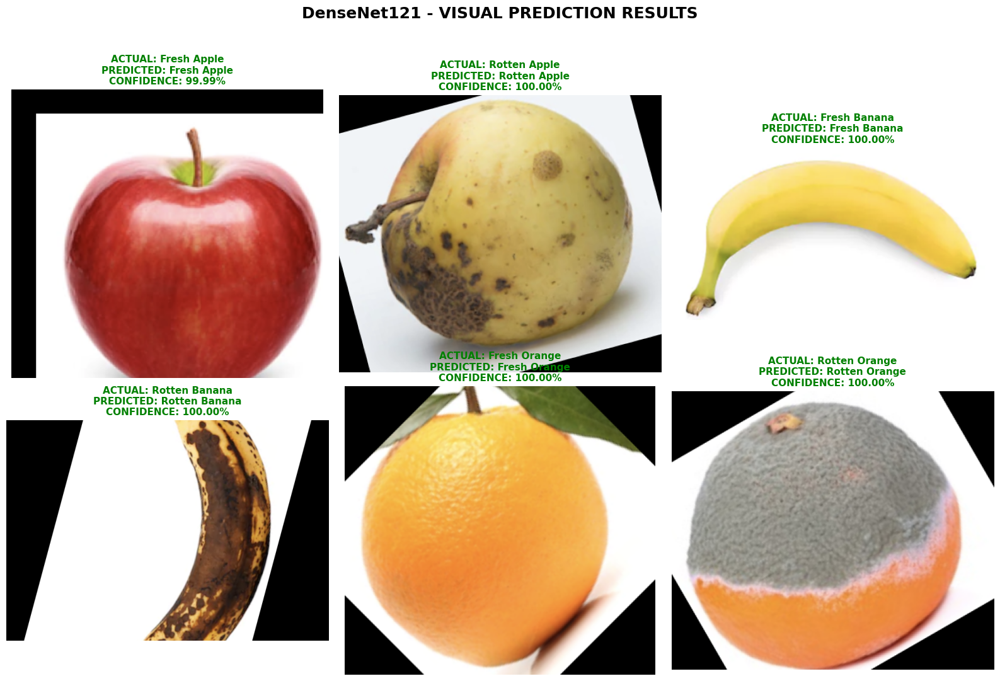


Visual output saved: /content/drive/MyDrive/dataset/results/predictions/visual_predictions/DenseNet121_visual_predictions.png


###########################################################################
MODEL 4/10: DenseNet169
###########################################################################

Predicting: Fresh Apple
Actual: Fresh Apple
Predicted: Fresh Apple
Confidence: 100.0 %
Result: CORRECT

Predicting: Rotten Apple
Actual: Rotten Apple
Predicted: Rotten Apple
Confidence: 99.81 %
Result: CORRECT

Predicting: Fresh Banana
Actual: Fresh Banana
Predicted: Fresh Banana
Confidence: 100.0 %
Result: CORRECT

Predicting: Rotten Banana
Actual: Rotten Banana
Predicted: Rotten Banana
Confidence: 100.0 %
Result: CORRECT

Predicting: Fresh Orange
Actual: Fresh Orange
Predicted: Fresh Orange
Confidence: 100.0 %
Result: CORRECT

Predicting: Rotten Orange
Actual: Rotten Orange
Predicted: Rotten Orange
Confidence: 100.0 %
Result: CORRECT


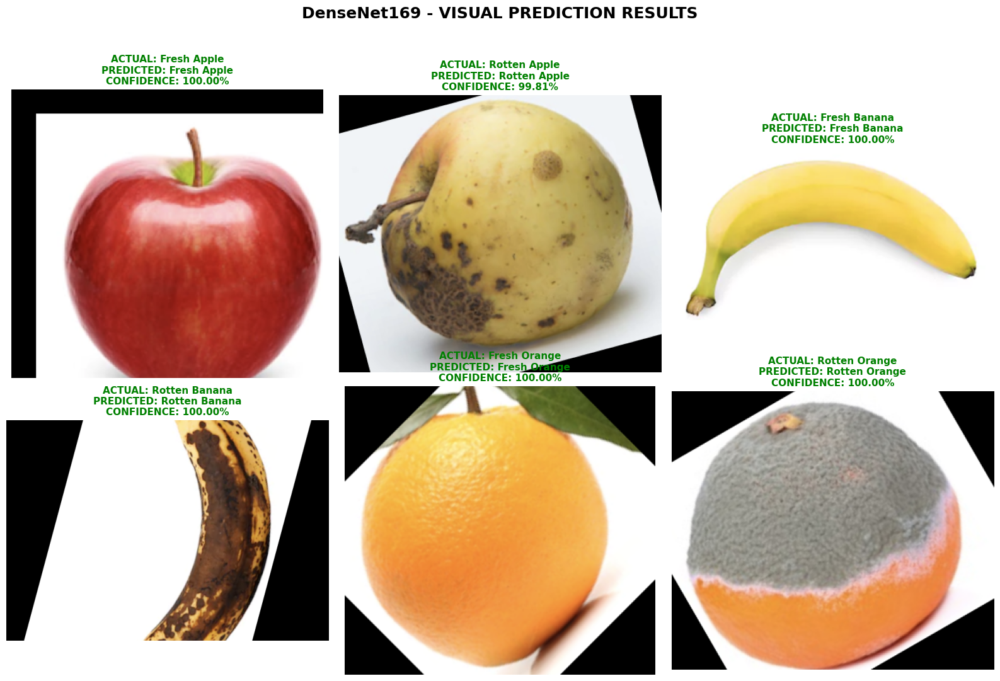


Visual output saved: /content/drive/MyDrive/dataset/results/predictions/visual_predictions/DenseNet169_visual_predictions.png


###########################################################################
MODEL 5/10: EfficientNetB0
###########################################################################

Predicting: Fresh Apple
Actual: Fresh Apple
Predicted: Fresh Apple
Confidence: 100.0 %
Result: CORRECT

Predicting: Rotten Apple
Actual: Rotten Apple
Predicted: Rotten Apple
Confidence: 100.0 %
Result: CORRECT

Predicting: Fresh Banana
Actual: Fresh Banana
Predicted: Fresh Banana
Confidence: 100.0 %
Result: CORRECT

Predicting: Rotten Banana
Actual: Rotten Banana
Predicted: Rotten Banana
Confidence: 100.0 %
Result: CORRECT

Predicting: Fresh Orange
Actual: Fresh Orange
Predicted: Fresh Orange
Confidence: 100.0 %
Result: CORRECT

Predicting: Rotten Orange
Actual: Rotten Orange
Predicted: Rotten Orange
Confidence: 100.0 %
Result: CORRECT


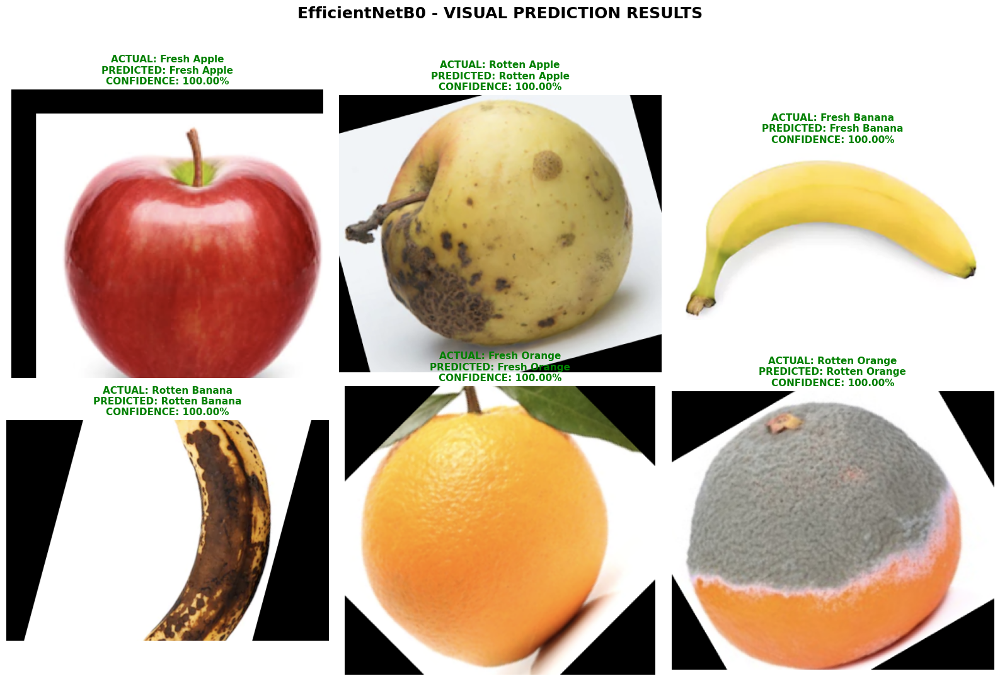


Visual output saved: /content/drive/MyDrive/dataset/results/predictions/visual_predictions/EfficientNetB0_visual_predictions.png


###########################################################################
MODEL 6/10: EfficientNetB1
###########################################################################

Predicting: Fresh Apple
Actual: Fresh Apple
Predicted: Fresh Apple
Confidence: 100.0 %
Result: CORRECT

Predicting: Rotten Apple
Actual: Rotten Apple
Predicted: Rotten Apple
Confidence: 100.0 %
Result: CORRECT

Predicting: Fresh Banana
Actual: Fresh Banana
Predicted: Fresh Banana
Confidence: 100.0 %
Result: CORRECT

Predicting: Rotten Banana
Actual: Rotten Banana
Predicted: Rotten Banana
Confidence: 100.0 %
Result: CORRECT

Predicting: Fresh Orange
Actual: Fresh Orange
Predicted: Fresh Orange
Confidence: 100.0 %
Result: CORRECT

Predicting: Rotten Orange
Actual: Rotten Orange
Predicted: Rotten Orange
Confidence: 100.0 %
Result: CORRECT


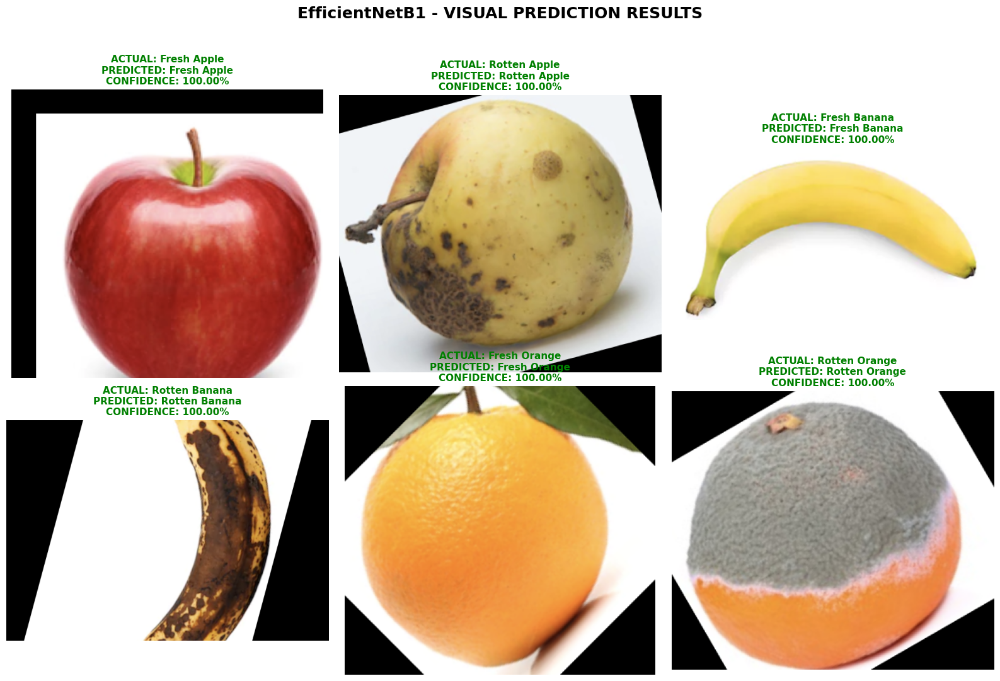


Visual output saved: /content/drive/MyDrive/dataset/results/predictions/visual_predictions/EfficientNetB1_visual_predictions.png


###########################################################################
MODEL 7/10: MobileNetV2
###########################################################################

Predicting: Fresh Apple
Actual: Fresh Apple
Predicted: Fresh Apple
Confidence: 99.99 %
Result: CORRECT

Predicting: Rotten Apple
Actual: Rotten Apple
Predicted: Rotten Apple
Confidence: 100.0 %
Result: CORRECT

Predicting: Fresh Banana
Actual: Fresh Banana
Predicted: Fresh Banana
Confidence: 100.0 %
Result: CORRECT

Predicting: Rotten Banana
Actual: Rotten Banana
Predicted: Rotten Banana
Confidence: 100.0 %
Result: CORRECT

Predicting: Fresh Orange
Actual: Fresh Orange
Predicted: Fresh Orange
Confidence: 100.0 %
Result: CORRECT

Predicting: Rotten Orange
Actual: Rotten Orange
Predicted: Rotten Orange
Confidence: 99.79 %
Result: CORRECT


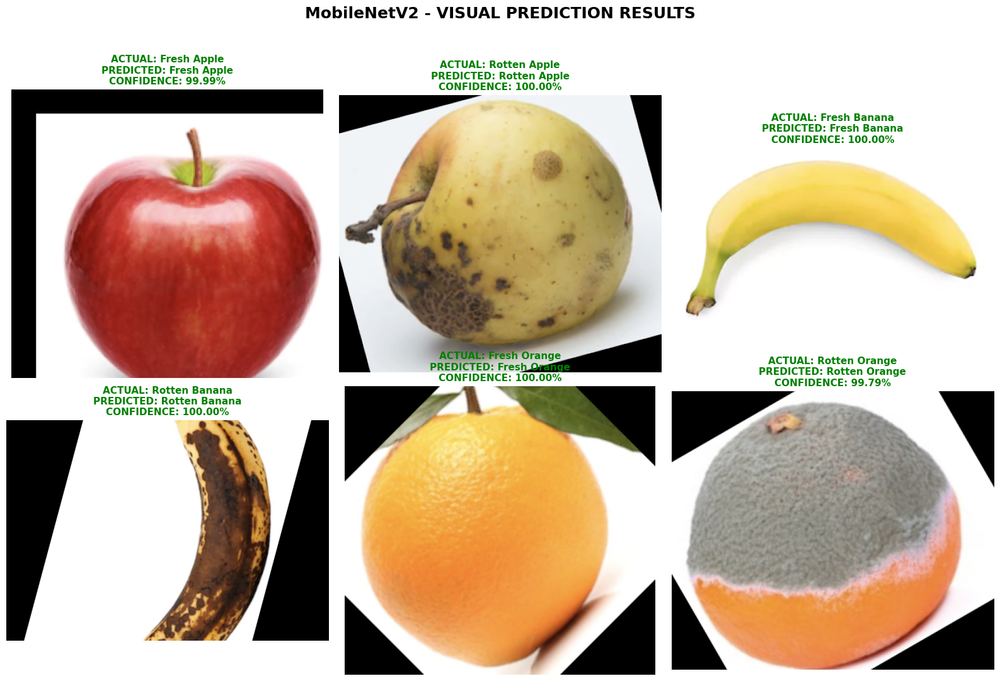


Visual output saved: /content/drive/MyDrive/dataset/results/predictions/visual_predictions/MobileNetV2_visual_predictions.png


###########################################################################
MODEL 8/10: MobileNetV3Large
###########################################################################

Predicting: Fresh Apple
Actual: Fresh Apple
Predicted: Fresh Apple
Confidence: 100.0 %
Result: CORRECT

Predicting: Rotten Apple
Actual: Rotten Apple
Predicted: Rotten Apple
Confidence: 100.0 %
Result: CORRECT

Predicting: Fresh Banana
Actual: Fresh Banana
Predicted: Fresh Banana
Confidence: 100.0 %
Result: CORRECT

Predicting: Rotten Banana
Actual: Rotten Banana
Predicted: Rotten Banana
Confidence: 100.0 %
Result: CORRECT

Predicting: Fresh Orange
Actual: Fresh Orange
Predicted: Fresh Orange
Confidence: 100.0 %
Result: CORRECT

Predicting: Rotten Orange
Actual: Rotten Orange
Predicted: Rotten Orange
Confidence: 100.0 %
Result: CORRECT


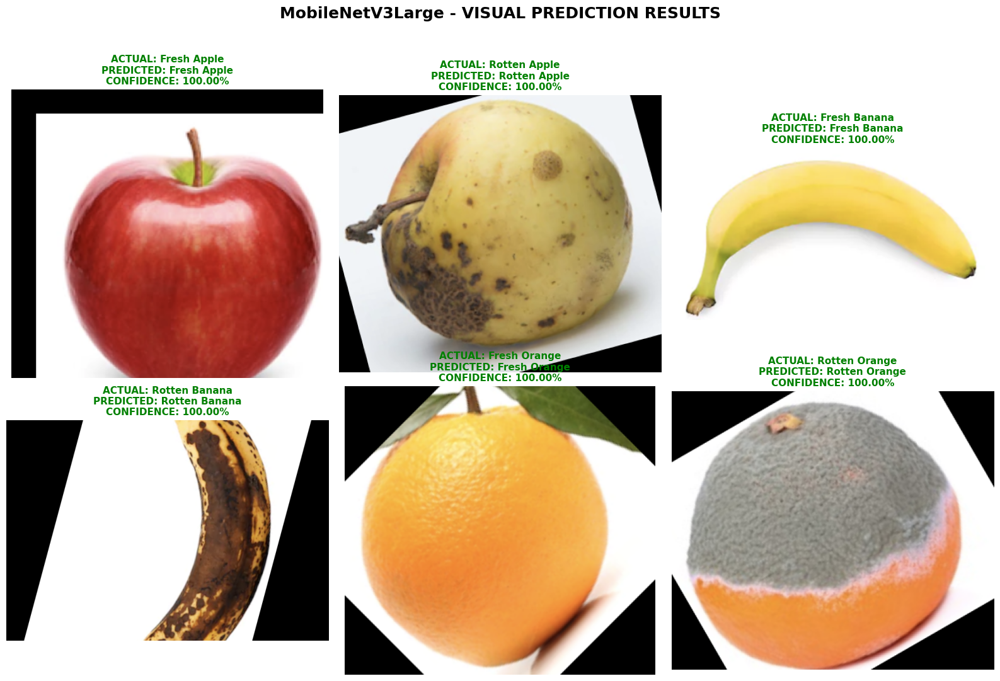


Visual output saved: /content/drive/MyDrive/dataset/results/predictions/visual_predictions/MobileNetV3Large_visual_predictions.png


###########################################################################
MODEL 9/10: InceptionV3
###########################################################################

Predicting: Fresh Apple
Actual: Fresh Apple
Predicted: Fresh Apple
Confidence: 99.75 %
Result: CORRECT

Predicting: Rotten Apple
Actual: Rotten Apple
Predicted: Rotten Apple
Confidence: 100.0 %
Result: CORRECT

Predicting: Fresh Banana
Actual: Fresh Banana
Predicted: Fresh Banana
Confidence: 100.0 %
Result: CORRECT

Predicting: Rotten Banana
Actual: Rotten Banana
Predicted: Rotten Banana
Confidence: 100.0 %
Result: CORRECT

Predicting: Fresh Orange
Actual: Fresh Orange
Predicted: Fresh Orange
Confidence: 99.99 %
Result: CORRECT

Predicting: Rotten Orange
Actual: Rotten Orange
Predicted: Rotten Orange
Confidence: 100.0 %
Result: CORRECT


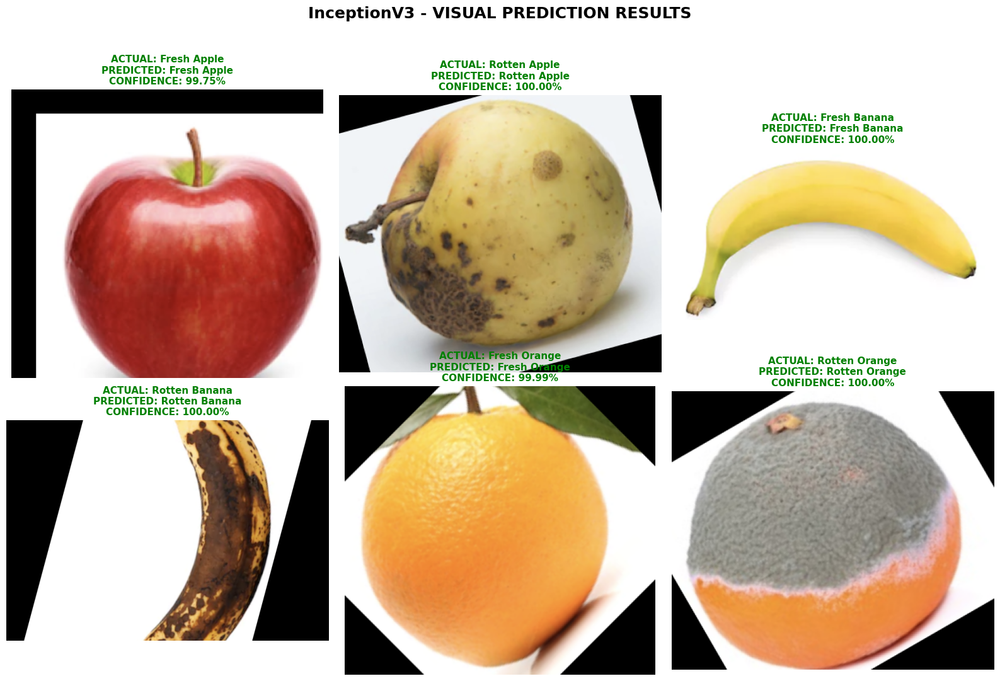


Visual output saved: /content/drive/MyDrive/dataset/results/predictions/visual_predictions/InceptionV3_visual_predictions.png


###########################################################################
MODEL 10/10: Xception
###########################################################################

Predicting: Fresh Apple
Actual: Fresh Apple
Predicted: Fresh Apple
Confidence: 99.68 %
Result: CORRECT

Predicting: Rotten Apple
Actual: Rotten Apple
Predicted: Rotten Apple
Confidence: 100.0 %
Result: CORRECT

Predicting: Fresh Banana
Actual: Fresh Banana
Predicted: Fresh Banana
Confidence: 100.0 %
Result: CORRECT

Predicting: Rotten Banana
Actual: Rotten Banana
Predicted: Rotten Banana
Confidence: 100.0 %
Result: CORRECT

Predicting: Fresh Orange
Actual: Fresh Orange
Predicted: Fresh Orange
Confidence: 100.0 %
Result: CORRECT

Predicting: Rotten Orange
Actual: Rotten Orange
Predicted: Rotten Orange
Confidence: 100.0 %
Result: CORRECT


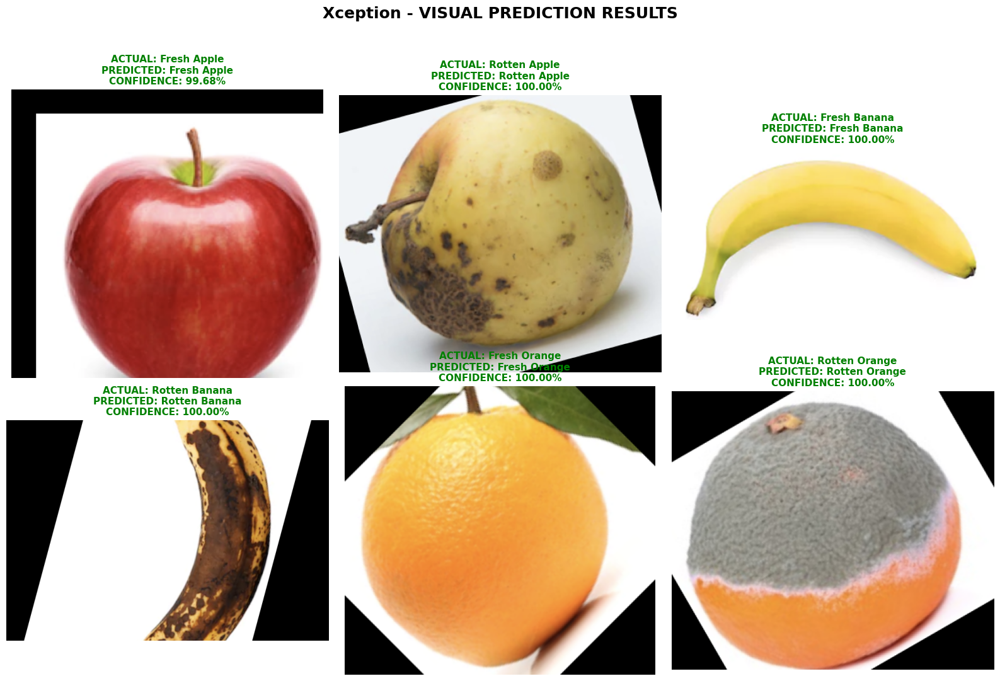


Visual output saved: /content/drive/MyDrive/dataset/results/predictions/visual_predictions/Xception_visual_predictions.png


FINAL RESULTS - ALL MODELS AND ALL IMAGES


,Model,Image,Actual,Predicted,Predicted Condition,Confidence (%),GOOD Probability (%),ROTTEN Probability (%),Correct,Status
0,ResNet50,translation_Screen Shot 2018-06-08 at 5.15.39 ...,Fresh Apple,Fresh Apple,Fresh,99.93,99.93,0.07,True,SUCCESS
1,ResNet50,rotated_by_15_Screen Shot 2018-06-07 at 3.00.0...,Rotten Apple,Rotten Apple,Rotten,100.00,0.00,100.00,True,SUCCESS
2,ResNet50,Screen Shot 2018-06-12 at 9.39.13 PM.png,Fresh Banana,Fresh Banana,Fresh,100.00,100.00,0.00,True,SUCCESS
3,ResNet50,rotated_by_75_Screen Shot 2018-06-12 at 8.47.4...,Rotten Banana,Rotten Banana,Rotten,100.00,0.00,100.00,True,SUCCESS
4,ResNet50,rotated_by_45_Screen Shot 2018-06-12 at 11.52....,Fresh Orange,Fresh Orange,Fresh,100.00,100.00,0.00,True,SUCCESS
5,ResNet50,rotated_by_30_Screen Shot 2018-06-12 at 11.40....,Rotten Orange,Rotten Orange,Rotten,100.00,0.00,100.00,True,SUCCESS
6,ResNet101,translation_Screen Shot 2018-06-08 at 5.15.39 ...,Fresh Apple,Fresh Apple,Fresh,99.99,99.99,0.01,True,SUCCESS
7,ResNet101,rotated_by_15_Screen Shot 2018-06-07 at 3.00.0...,Rotten Apple,Rotten Apple,Rotten,100.00,0.00,100.00,True,SUCCESS
8,ResNet101,Screen Shot 2018-06-12 at 9.39.13 PM.png,Fresh Banana,Fresh Banana,Fresh,100.00,100.00,0.00,True,SUCCESS
9,ResNet101,rotated_by_75_Screen Shot 2018-06-12 at 8.47.4...,Rotten Banana,Rotten Banana,Rotten,100.00,0.00,100.00,True,SUCCESS



MODEL-WISE VISUAL PREDICTION ACCURACY


,Model,Correct_Predictions,Total_Images,Accuracy (%)
0,DenseNet121,6,6,100.0
1,DenseNet169,6,6,100.0
2,EfficientNetB0,6,6,100.0
3,EfficientNetB1,6,6,100.0
4,InceptionV3,6,6,100.0
5,MobileNetV2,6,6,100.0
6,MobileNetV3Large,6,6,100.0
7,ResNet101,6,6,100.0
8,ResNet50,6,6,100.0
9,Xception,6,6,100.0


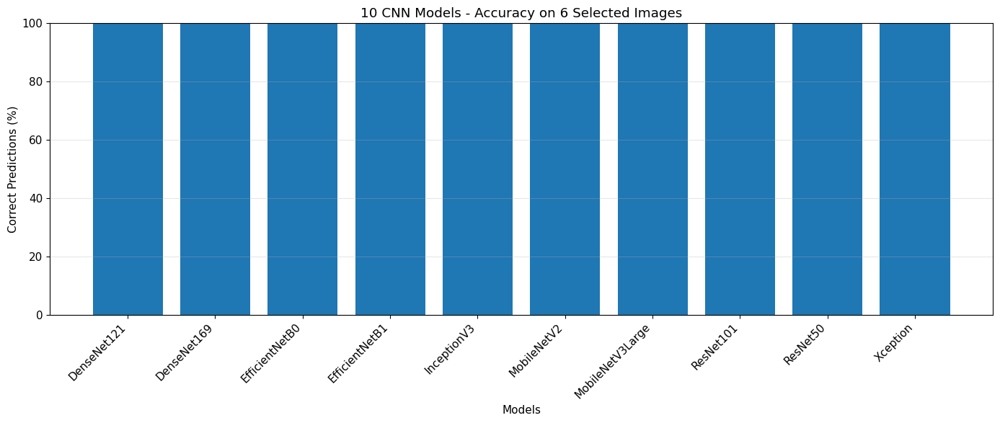



VISUAL PREDICTION COMPLETED
Total Models: 10
Selected Images: 6
Total Prediction Attempts: 60
Successful Predictions: 60

All results saved in:
/content/drive/MyDrive/dataset/results/predictions/visual_predictions

CSV File:
/content/drive/MyDrive/dataset/results/predictions/visual_predictions/all_10_models_6_image_predictions.csv

AIDL PROJECT COMPLETED


In [ ]:

# ================================================================
# AIDL PROJECT
# VISUAL FRUIT FRESHNESS PREDICTION USING 10 CNN MODELS
# 6 TEST IMAGES x 10 MODELS = 60 PREDICTIONS
# NO TRAINING
# ================================================================

import os
import gc
import glob
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display

# ================================================================
# 1. IMPORT MODEL PREPROCESSING FUNCTIONS
# ================================================================

from tensorflow.keras.applications.resnet import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.applications.inception_v3 import preprocess_input as inception_preprocess
from tensorflow.keras.applications.xception import preprocess_input as xception_preprocess

print("TensorFlow Version:", tf.__version__)


# ================================================================
# 2. GOOGLE DRIVE
# ================================================================

from google.colab import drive

drive.mount('/content/drive')

BASE_PATH = "/content/drive/MyDrive/dataset"

TEST_PATH = os.path.join(
    BASE_PATH, "dataset", "test"
)

RESULTS_PATH = os.path.join(
    BASE_PATH, "results"
)

SAVED_MODELS_PATH = os.path.join(
    RESULTS_PATH, "saved_models"
)

OUTPUT_PATH = os.path.join(
    RESULTS_PATH, "predictions", "visual_predictions"
)

os.makedirs(
    OUTPUT_PATH,
    exist_ok=True
)

print("\nTest Folder:", TEST_PATH)
print("Saved Models:", SAVED_MODELS_PATH)
print("Output Folder:", OUTPUT_PATH)


# ================================================================
# 3. SIX FRUIT CLASSES
# ================================================================

FRUIT_CLASSES = {

    "freshapples": {
        "fruit": "Apple",
        "condition": "Fresh",
        "label": "Fresh Apple"
    },

    "rottenapples": {
        "fruit": "Apple",
        "condition": "Rotten",
        "label": "Rotten Apple"
    },

    "freshbanana": {
        "fruit": "Banana",
        "condition": "Fresh",
        "label": "Fresh Banana"
    },

    "rottenbanana": {
        "fruit": "Banana",
        "condition": "Rotten",
        "label": "Rotten Banana"
    },

    "freshoranges": {
        "fruit": "Orange",
        "condition": "Fresh",
        "label": "Fresh Orange"
    },

    "rottenoranges": {
        "fruit": "Orange",
        "condition": "Rotten",
        "label": "Rotten Orange"
    }
}


# ================================================================
# 4. TEN TRAINED MODELS
# ================================================================

MODEL_CONFIGS = {

    "ResNet50": {
        "size": 224,
        "preprocess": resnet_preprocess
    },

    "ResNet101": {
        "size": 224,
        "preprocess": resnet_preprocess
    },

    "DenseNet121": {
        "size": 224,
        "preprocess": densenet_preprocess
    },

    "DenseNet169": {
        "size": 224,
        "preprocess": densenet_preprocess
    },

    "EfficientNetB0": {
        "size": 224,
        "preprocess": None
    },

    "EfficientNetB1": {
        "size": 240,
        "preprocess": None
    },

    "MobileNetV2": {
        "size": 224,
        "preprocess": mobilenet_preprocess
    },

    "MobileNetV3Large": {
        "size": 224,
        "preprocess": None
    },

    "InceptionV3": {
        "size": 299,
        "preprocess": inception_preprocess
    },

    "Xception": {
        "size": 299,
        "preprocess": xception_preprocess
    }
}

MODEL_NAMES = list(MODEL_CONFIGS.keys())


# ================================================================
# 5. SELECT ONE IMAGE FROM EACH OF SIX FOLDERS
# ================================================================

random.seed(42)

IMAGE_EXTENSIONS = (
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
)

selected_images = []

print("\nSELECTING SIX TEST IMAGES")
print("=" * 65)

for folder_name, details in FRUIT_CLASSES.items():

    folder_path = os.path.join(
        TEST_PATH,
        folder_name
    )

    if not os.path.isdir(folder_path):

        raise FileNotFoundError(
            "Missing class folder: " + folder_path
        )

    images = []

    for ext in IMAGE_EXTENSIONS:

        images.extend(
            glob.glob(
                os.path.join(folder_path, "**", "*" + ext),
                recursive=True
            )
        )

        images.extend(
            glob.glob(
                os.path.join(folder_path, "**", "*" + ext.upper()),
                recursive=True
            )
        )

    images = sorted(set(images))

    if len(images) == 0:

        raise ValueError(
            "No images found in " + folder_path
        )

    # Select one reproducible random image
    selected_path = random.choice(images)

    selected_images.append({

        "path": selected_path,

        "folder": folder_name,

        "actual": details["label"],

        "fruit": details["fruit"],

        "condition": details["condition"]

    })

    print(
        details["label"],
        "->",
        os.path.basename(selected_path)
    )

print("\nTotal Selected Images:", len(selected_images))


# ================================================================
# 6. DISPLAY THE SIX SELECTED TEST IMAGES
# ================================================================

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 9)
)

for ax, item in zip(
    axes.flatten(),
    selected_images
):

    img = Image.open(
        item["path"]
    ).convert("RGB")

    ax.imshow(img)

    ax.set_title(
        "ACTUAL: " + item["actual"],
        fontsize=12,
        fontweight="bold"
    )

    ax.axis("off")

plt.suptitle(
    "SIX SELECTED TEST IMAGES",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()

selected_grid_path = os.path.join(
    OUTPUT_PATH,
    "six_selected_test_images.png"
)

plt.savefig(
    selected_grid_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 7. LOAD SAVED MODEL WITH CUSTOM PREPROCESSING
# ================================================================

def load_saved_model(model_name):

    model_path = os.path.join(
        SAVED_MODELS_PATH,
        model_name + ".keras"
    )

    if not os.path.exists(model_path):

        raise FileNotFoundError(
            "Saved model missing: " + model_path
        )

    preprocess_function = MODEL_CONFIGS[
        model_name
    ]["preprocess"]

    custom_objects = {}

    if preprocess_function is not None:

        custom_objects = {
            "preprocess_input": preprocess_function
        }

    model = tf.keras.models.load_model(

        model_path,

        custom_objects=custom_objects,

        compile=False,

        safe_mode=False

    )

    return model


# ================================================================
# 8. IMAGE PREDICTION
# ================================================================

def predict_single_image(
    model,
    model_name,
    image_path
):

    image_size = MODEL_CONFIGS[
        model_name
    ]["size"]

    image = Image.open(
        image_path
    ).convert("RGB")

    image = image.resize(
        (image_size, image_size)
    )

    image_array = np.array(
        image,
        dtype=np.float32
    )

    image_array = np.expand_dims(
        image_array,
        axis=0
    )

    # Preprocessing is already part of the saved model.
    # Input is kept in the original 0-255 scale.

    probability = model.predict(
        image_array,
        verbose=0
    )

    rotten_probability = float(
        probability.reshape(-1)[0]
    )

    good_probability = (
        1.0 - rotten_probability
    )

    if rotten_probability >= 0.5:

        predicted_condition = "Rotten"

        confidence = rotten_probability * 100

    else:

        predicted_condition = "Fresh"

        confidence = good_probability * 100

    return (
        predicted_condition,
        confidence,
        good_probability * 100,
        rotten_probability * 100
    )


# ================================================================
# 9. RUN ALL TEN MODELS ON ALL SIX IMAGES
# ================================================================

all_results = []

print("\n")
print("=" * 80)
print("STARTING VISUAL PREDICTION")
print("10 MODELS x 6 IMAGES = 60 PREDICTIONS")
print("=" * 80)

for model_number, model_name in enumerate(
    MODEL_NAMES, start=1
):

    print("\n")
    print("#" * 75)
    print(
        f"MODEL {model_number}/10: {model_name}"
    )
    print("#" * 75)

    tf.keras.backend.clear_session()
    gc.collect()

    try:

        # Load model only once
        model = load_saved_model(
            model_name
        )

        # Create a separate image grid for each model
        fig, axes = plt.subplots(
            2, 3,
            figsize=(16, 11)
        )

        axes = axes.flatten()

        for image_number, item in enumerate(
            selected_images
        ):

            print(
                "\nPredicting:",
                item["actual"]
            )

            (
                predicted_condition,
                confidence,
                good_probability,
                rotten_probability
            ) = predict_single_image(

                model,

                model_name,

                item["path"]

            )

            # Fruit identity comes from the test folder.
            # The saved model predicts Fresh or Rotten.

            predicted_label = (
                predicted_condition + " " + item["fruit"]
            )

            actual_label = item["actual"]

            is_correct = (
                predicted_label == actual_label
            )

            print("Actual:", actual_label)

            print("Predicted:", predicted_label)

            print(
                "Confidence:",
                round(confidence, 2),
                "%"
            )

            print(
                "Result:",
                "CORRECT" if is_correct else "INCORRECT"
            )

            # Save tabular result
            all_results.append({

                "Model": model_name,

                "Image": os.path.basename(
                    item["path"]
                ),

                "Actual": actual_label,

                "Predicted": predicted_label,

                "Predicted Condition": predicted_condition,

                "Confidence (%)": round(
                    confidence, 2
                ),

                "GOOD Probability (%)": round(
                    good_probability, 2
                ),

                "ROTTEN Probability (%)": round(
                    rotten_probability, 2
                ),

                "Correct": is_correct,

                "Status": "SUCCESS"

            })

            # Display original image
            original = Image.open(
                item["path"]
            ).convert("RGB")

            ax = axes[image_number]

            ax.imshow(original)

            # Actual and predicted labels
            ax.set_title(

                f"ACTUAL: {actual_label}\n"
                f"PREDICTED: {predicted_label}\n"
                f"CONFIDENCE: {confidence:.2f}%",

                fontsize=11,

                fontweight="bold",

                color="green" if is_correct else "red"

            )

            ax.axis("off")

        # Model heading
        plt.suptitle(

            f"{model_name} - VISUAL PREDICTION RESULTS",

            fontsize=18,

            fontweight="bold"

        )

        plt.tight_layout(
            rect=[0, 0, 1, 0.94]
        )

        # Save individual model's visual output
        figure_path = os.path.join(

            OUTPUT_PATH,

            model_name + "_visual_predictions.png"

        )

        plt.savefig(

            figure_path,

            dpi=160,

            bbox_inches="tight"

        )

        plt.show()

        plt.close(fig)

        print(
            "\nVisual output saved:",
            figure_path
        )

        del model

    except Exception as error:

        print(
            "\nMODEL FAILED:",
            model_name,
            str(error)
        )

        # Record failures for all six images
        for item in selected_images:

            all_results.append({

                "Model": model_name,

                "Image": os.path.basename(
                    item["path"]
                ),

                "Actual": item["actual"],

                "Predicted": "ERROR",

                "Predicted Condition": "ERROR",

                "Confidence (%)": 0,

                "GOOD Probability (%)": 0,

                "ROTTEN Probability (%)": 0,

                "Correct": False,

                "Status": "FAILED"

            })

    finally:

        gc.collect()


# ================================================================
# 10. FINAL COMPARISON TABLE
# ================================================================

results_df = pd.DataFrame(
    all_results
)

print("\n")
print("=" * 85)
print("FINAL RESULTS - ALL MODELS AND ALL IMAGES")
print("=" * 85)

display(results_df)


# ================================================================
# 11. MODEL-WISE ACCURACY ON SIX SELECTED IMAGES
# ================================================================

successful_df = results_df[
    results_df["Status"] == "SUCCESS"
]

if not successful_df.empty:

    accuracy_df = (
        successful_df.groupby("Model")
        .agg(
            Correct_Predictions=("Correct", "sum"),

            Total_Images=("Correct", "count")
        )
        .reset_index()
    )

    accuracy_df["Accuracy (%)"] = (

        accuracy_df["Correct_Predictions"]

        / accuracy_df["Total_Images"]

        * 100

    ).round(2)

    print("\nMODEL-WISE VISUAL PREDICTION ACCURACY")

    display(accuracy_df)

    plt.figure(figsize=(14, 6))

    plt.bar(
        accuracy_df["Model"],
        accuracy_df["Accuracy (%)"]
    )

    plt.title(
        "10 CNN Models - Accuracy on 6 Selected Images"
    )

    plt.xlabel("Models")

    plt.ylabel("Correct Predictions (%)")

    plt.ylim(0, 100)

    plt.xticks(
        rotation=45,
        ha="right"
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_PATH,
            "model_accuracy_comparison.png"
        ),
        dpi=150
    )

    plt.show()


# ================================================================
# 12. SAVE CSV RESULTS TO GOOGLE DRIVE
# ================================================================

csv_path = os.path.join(
    OUTPUT_PATH,
    "all_10_models_6_image_predictions.csv"
)

results_df.to_csv(
    csv_path,
    index=False
)

print("\n")
print("=" * 80)
print("VISUAL PREDICTION COMPLETED")
print("=" * 80)

print("Total Models:", len(MODEL_NAMES))

print("Selected Images:", len(selected_images))

print("Total Prediction Attempts:", len(results_df))

print(
    "Successful Predictions:",
    len(successful_df)
)

print("\nAll results saved in:")

print(OUTPUT_PATH)

print("\nCSV File:")

print(csv_path)

print("\nAIDL PROJECT COMPLETED")
